# Tarea 03: Generación de imágenes con autoencoders
### PyTorch Lightning · Hydra · Weights & Biases
**Curso:** Inteligencia Artificial (IC6200) , Instituto Tecnológico de Costa Rica
**Estudiantes:** Joshua Obando · Daniel Zeas
**Proyecto WandB:** https://forge.coreweave.com/wandb/danielzeasbrown-instituto-tecnologico-de-costa-rica/tarea03-autoencoder/runs/lu6osh4y?nw=nwuserjos_obando



## 0. Preparación
Conexión con WandB para descargar las métricas e imágenes de los experimentos. Los entrenamientos y sus salidas están en la sección 4.5.


In [ ]:
!pip install -q wandb
import os, re, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import wandb
from IPython.display import Image, display, Markdown
wandb.login()
api = wandb.Api()

PROJECT = 'tarea03-autoencoder'
# Buscar automáticamente el espacio (entity) donde están los runs
candidatos = [api.default_entity]
try:
    candidatos += [t for t in api.viewer.teams if t not in candidatos]
except Exception:
    pass
ENTITY = None
for e in candidatos:
    try:
        if len(api.runs(f'{e}/{PROJECT}')) > 0:
            ENTITY = e; break
    except Exception:
        pass
assert ENTITY, f'No encontré el proyecto en {candidatos}: escribir ENTITY a mano'
print('Entity:', ENTITY)

# Código del proyecto (para mostrar las configuraciones de Hydra)
if not os.path.exists('/content/tarea03'):
    !git clone -q https://github.com/joshuaobandotec/2026-02-IC6200-tarea03-autoencoder.git /content/tarea03

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: jos_obando (jos_obando-tecnol-gico-de-costa-rica) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Entity: danielzeasbrown-instituto-tecnologico-de-costa-rica


In [ ]:
# Runs de WandB: fase 1 (grupos vae / unet) y fase 2 (grupo extras)
LOSSES = ['l1', 'l2', 'ssim', 'ssim_l1']
todos = [r for r in api.runs(f'{ENTITY}/{PROJECT}') if r.state == 'finished']
def ultimo(nombre):
    c = [r for r in todos if r.name == nombre]
    return max(c, key=lambda r: r.created_at) if c else None

fase1 = {m: {l: ultimo(f'{m}-{l}') for l in LOSSES} for m in ['vae', 'unet']}
extras = {}
for r in todos:
    if r.group == 'extras':
        extras[r.name] = ultimo(r.name)
for m in fase1:
    print(m, {l: ('OK' if r else 'FALTA') for l, r in fase1[m].items()})
print('extras:', list(extras))

vae {'l1': 'OK', 'l2': 'OK', 'ssim': 'OK', 'ssim_l1': 'OK'}
unet {'l1': 'OK', 'l2': 'OK', 'ssim': 'OK', 'ssim_l1': 'OK'}
extras: ['vae-ssim_l1-z32', 'vae-ssim_l1-z128', 'vae-ssim_l1-kl0.001', 'vae-ssim_l1-kl0.01', 'unet-ssim_l1-sin-skips-altas']


In [ ]:
# Utilidades: descargar imágenes registradas en WandB
def imagenes(run, clave):
    """Descarga las imágenes de `clave` (p.ej. 'val/reconstrucciones') ordenadas por step."""
    destino = f'wandb_imgs/{run.name}'
    archivos = [f for f in run.files() if f.name.startswith(f'media/images/{clave}_')]
    def step(f):
        m = re.search(r'_(\d+)_[0-9a-f]+\.png$', f.name)
        return int(m.group(1)) if m else 0
    rutas = []
    for f in sorted(archivos, key=step):
        f.download(root=destino, exist_ok=True)
        rutas.append(os.path.join(destino, f.name))
    return rutas

def mostrar(run, clave, cual=-1, ancho=900):
    rutas = imagenes(run, clave)
    if not rutas:
        print(f'(sin imágenes {clave} en {run.name})'); return
    display(Markdown(f'**{run.name}** — `{clave}`'))
    display(Image(rutas[cual], width=ancho))

## 1. Objetivo

El objetivo es construir un detector de anomalías no supervisado para control de calidad industrial. La idea es simple: entrenamos un autoencoder solo con piezas sin defectos, para que aprenda a reconstruir lo "normal". Cuando le llega una pieza con un defecto, que nunca vio en entrenamiento, la reconstruye mal. Esa diferencia entre la imagen original y la reconstruida, el error de reconstrucción, se vuelve la señal de anomalía: a mayor error, más probable que haya un defecto.

Comparamos dos arquitecturas, un VAE y un autoencoder U-Net con skip connections, bajo cuatro pérdidas (L1, L2, SSIM y SSIM+L1), y medimos qué tan bien el error separa piezas buenas de defectuosas en el set de prueba.


## 2. Dataset: MVTec AD

[MVTec AD](https://www.mvtec.com/company/research/datasets/mvtec-ad) es un dataset de referencia para detectar anomalías en escenarios industriales reales: fotos de objetos y texturas con distintos defectos. Para reducir el tiempo de cómputo usamos solo 4 categorías, cable, capsule, screw y transistor, redimensionadas a 128×128×3.

Conteos por categoría (train = solo buenas, test = buenas más defectuosas):

| Categoría | train (buenas) | test |
|---|---|---|
| cable | 224 | 150 |
| capsule | 219 | 132 |
| screw | 320 | 160 |
| transistor | 213 | 100 |

Y sus subclases de defecto:

| Categoría | Subclases de defecto |
|---|---|
| cable | bent_wire, cable_swap, combined, cut_inner_insulation, cut_outer_insulation, missing_cable, missing_wire, poke_insulation |
| capsule | crack, faulty_imprint, poke, scratch, squeeze |
| screw | manipulated_front, scratch_head, scratch_neck, thread_side, thread_top |
| transistor | bent_lead, cut_lead, damaged_case, misplaced |

La estructura en disco es train/good/ (solo piezas buenas) y test/<good | subclase_defecto>/.

Decisión de diseño: entrenamiento y validación usan solo imágenes buenas, repartidas 85 % / 15 %; el set de prueba incluye buenas y defectuosas, etiquetadas por subclase. Es lo que pide el enfoque no supervisado: el modelo jamás ve un defecto en entrenamiento, así que su desempeño en prueba refleja si aprendió lo normal y falla ante lo anómalo.

Nota: screw viene en escala de grises; se convierte a 3 canales para que todas las categorías tengan la misma forma de entrada.


## 3. Configuración con Hydra
La configuración está separada en módulos: modelo, entrenamiento, logger y datos. Cualquier valor se puede cambiar desde la línea de comandos sin tocar el código.

In [ ]:
!cd /content/tarea03 && find conf -name '*.yaml' | sort
for f in ['conf/config.yaml', 'conf/model/vae.yaml', 'conf/model/u-net.yaml',
          'conf/trainer/default.yaml', 'conf/logger/wandb.yaml', 'conf/data/mvtec.yaml']:
    print(f'\n# ---------- {f} ----------')
    print(open(f'/content/tarea03/{f}').read())

conf/config.yaml
conf/data/mvtec.yaml
conf/logger/wandb.yaml
conf/model/u-net.yaml
conf/model/vae.yaml
conf/trainer/default.yaml

# ---------- conf/config.yaml ----------
# Configuración principal. Cambiar desde la línea de comandos, por ejemplo:
#   python train.py model=vae loss=ssim_l1
#   python train.py -m model=u-net loss=l1,l2,ssim,ssim_l1
defaults:
  - model: vae          # vae | u-net
  - trainer: default
  - logger: wandb
  - data: mvtec
  - _self_

# Función de pérdida de reconstrucción: l1 | l2 | ssim | ssim_l1
loss: l1
ssim_alpha: 0.5        # peso del SSIM en ssim_l1: alpha*(1-SSIM) + (1-alpha)*L1
lr: 1e-3
seed: 42

callbacks:
  recon_every_n_epochs: 1    # reconstrucciones de validación (16 imágenes)
  tsne_every_n_epochs: 10    # t-SNE del vector latente (es lo más lento)
  n_images: 16

hydra:
  run:
    dir: outputs/${model.name}-${loss}/${now:%Y-%m-%d_%H-%M-%S}
  sweep:
    dir: multirun/${now:%Y-%m-%d_%H-%M-%S}
    subdir: ${model.name}-${loss}


# ---------- conf/m

Hiperparámetros elegidos y por qué:

| Parámetro | Valor | Por qué |
|---|---|---|
| latent_dim | 64 | Suficiente para 4 clases de objetos a 128×128 sin sobredimensionar. En la fase 2, 32 y 128 rindieron peor en detección. |
| ssim_alpha | 0.5 | Las clases son objetos, no texturas; varios defectos son de color o forma (p. ej. cable_swap), donde L1 aporta. Con α=0.5 se equilibra estructura (SSIM) y detalle píxel a píxel (L1). |
| kl_weight (VAE) | 0.005 | Valor chico: regulariza el latente sin dominar sobre la reconstrucción. Bajarlo a 0.001 mejoró la detección en la fase 2. |
| max_epochs / batch_size / lr | 30 / 32 / 1e-3 | Iguales en todos los runs para que la única diferencia sea la pérdida. |


## 4. Modelos y entrenamiento

### 4.1 Variational Autoencoder (VAE)
El VAE usa un encoder convolucional que baja la imagen de 128×128 a un mapa de 8×8 (cuatro bloques de conv con stride 2), y de ahí proyecta a un vector latente z de 64 dimensiones. A diferencia de un autoencoder clásico, el encoder saca dos vectores: la media μ y el log de la varianza log σ². Con la reparametrización z = μ + σ·ε (con ε ~ N(0,I)) se muestrea z de forma diferenciable y se puede entrenar por backpropagation. El decoder es el espejo del encoder (ConvTranspose) y reconstruye la imagen con salida sigmoide en [0,1].

La pérdida tiene dos partes: reconstrucción (la pérdida elegida) más β·KL, donde KL mide qué tan lejos está q(z|x) de la gaussiana estándar N(0,I). El KL regulariza: obliga al latente a ser continuo y ordenado, lo que da reconstrucciones más borrosas pero un latente más útil para separar lo normal de lo anómalo.

### 4.2 Autoencoder U-Net
El U-Net sigue el mismo esquema encoder-latente-decoder, pero con skip connections: en cada nivel, las activaciones del encoder se concatenan con las del decoder a la misma resolución. Ventaja: el decoder recibe los detalles de alta frecuencia y las reconstrucciones salen mucho más nítidas. Riesgo: esas conexiones dejan pasar información por fuera del cuello de botella, así que el modelo puede copiar los defectos en vez de borrarlos, justo lo contrario de lo que queremos para detectar anomalías.

### 4.3 Funciones de pérdida
- L1 (l1): error absoluto medio. Robusto a valores atípicos, conserva el contraste medio.
- L2 (l2): error cuadrático medio. Penaliza fuerte los errores grandes, tiende a imágenes más suaves.
- SSIM (ssim): compara estructura, contraste y luminancia, no píxel a píxel. Minimizamos 1 - SSIM. Conserva bordes y texturas.
- SSIM + L1 (ssim_l1): combinación α(1-SSIM) + (1-α)L1 con α = 0.5. Junta estructura del SSIM con ajuste píxel a píxel del L1.

### 4.4 Ejecución
Los 8 experimentos de la fase 1 (2 modelos × 4 pérdidas, mismos hiperparámetros) se lanzaron con:
```bash
python train.py model=vae   loss=l1|l2|ssim|ssim_l1
python train.py model=u-net loss=l1|l2|ssim|ssim_l1
```


In [ ]:
# Tabla de los runs registrados en WandB
filas = []
for m in fase1:
    for l, r in fase1[m].items():
        if r: filas.append({'run': r.name, 'modelo': m, 'pérdida': l,
                            'latent_dim': r.config.get('model', {}).get('latent_dim'),
                            'épocas': r.config.get('trainer', {}).get('max_epochs'),
                            'duración (min)': round(r.summary.get('_runtime', 0) / 60, 1),
                            'link': r.url})
pd.DataFrame(filas)

,run,modelo,pérdida,latent_dim,épocas,duración (min),link
0,vae-l1,vae,l1,64,30,2.3,https://wandb.ai/danielzeasbrown-instituto-tec...
1,vae-l2,vae,l2,64,30,2.2,https://wandb.ai/danielzeasbrown-instituto-tec...
2,vae-ssim,vae,ssim,64,30,2.5,https://wandb.ai/danielzeasbrown-instituto-tec...
3,vae-ssim_l1,vae,ssim_l1,64,30,2.5,https://wandb.ai/danielzeasbrown-instituto-tec...
4,unet-l1,unet,l1,64,30,4.2,https://wandb.ai/danielzeasbrown-instituto-tec...
5,unet-l2,unet,l2,64,30,4.2,https://wandb.ai/danielzeasbrown-instituto-tec...
6,unet-ssim,unet,ssim,64,30,4.5,https://wandb.ai/danielzeasbrown-instituto-tec...
7,unet-ssim_l1,unet,ssim_l1,64,30,4.4,https://wandb.ai/danielzeasbrown-instituto-tec...


In [ ]:
from IPython.display import Code
for f in ['train.py', 'src/data.py', 'src/losses.py', 'src/models/vae.py',
          'src/models/unet.py', 'src/module.py', 'src/callbacks.py']:
    display(Markdown(f'#### `{f}`'))
    display(Code(filename=f'/content/tarea03/{f}', language='python'))

#### `train.py`

"""Punto de entrada. Ejemplos:

    # un experimento
    python train.py model=vae loss=l1

    # los 4 experimentos de un modelo (Hydra multirun)
    python train.py -m model=vae loss=l1,l2,ssim,ssim_l1
    python train.py -m model=u-net loss=l1,l2,ssim,ssim_l1

    # cambiar hiperparámetros
    python train.py model=vae model.latent_dim=64 trainer.max_epochs=50 data.batch_size=64
"""
import hydra
import lightning as L
import wandb
from hydra.core.hydra_config import HydraConfig
from hydra.utils import instantiate
from lightning.pytorch.callbacks import ModelCheckpoint
from lightning.pytorch.loggers import WandbLogger
from omegaconf import DictConfig, OmegaConf

from src.callbacks import LatentTSNECallback, ReconstructionCallback, TestEvaluationCallback
from src.data import MVTecDataModule
from src.module import AutoencoderModule


@hydra.main(version_base="1.3", config_path="conf", config_name="config")
def main(cfg: DictConfig):
    print(OmegaConf.to_yaml(cfg))
    L.seed_everything(cfg.seed, workers=True)
    out_dir = HydraConfig.get().runtime.output_dir

    # to_container: convierte las listas de Hydra a listas normales de Python
    # (si no, PyTorch >= 2.6 no puede volver a cargar el checkpoint)
    dm = MVTecDataModule(**OmegaConf.to_container(cfg.data, resolve=True))
    module = AutoencoderModule(
        net=instantiate(cfg.model.net), loss=cfg.loss, ssim_alpha=cfg.ssim_alpha,
        kl_weight=cfg.model.kl_weight, lr=cfg.lr,
    )

    logger = WandbLogger(
        project=cfg.logger.project, entity=cfg.logger.entity, group=cfg.logger.group,
        name=cfg.logger.name, mode=cfg.logger.mode, save_dir=out_dir,
        config=OmegaConf.to_container(cfg, resolve=True),
    )

    callbacks = [
        ModelCheckpoint(dirpath=f"{out_dir}/checkpoints", monitor="val/loss",
                        mode="min", save_top_k=1),
        ReconstructionCallback(cfg.callbacks.recon_every_n_epochs, cfg.callbacks.n_images),
        LatentTSNECallback(cfg.callbacks.tsne_every_n_epochs),
        TestEvaluationCallback(out_dir=out_dir, n_images=cfg.callbacks.n_images),
    ]

    trainer = L.Trainer(**cfg.trainer, logger=logger, callbacks=callbacks)
    trainer.fit(module, datamodule=dm)
    trainer.test(module, datamodule=dm, ckpt_path="best")
    wandb.finish()  # necesario para que cada run del multirun quede separado


if __name__ == "__main__":
    main()

#### `src/data.py`

"""DataModule de MVTec AD (Persona A).

Estructura esperada en disco (la del dataset oficial):
    root/<categoria>/train/good/*.png
    root/<categoria>/test/<good|tipo_defecto>/*.png

- train / val: solo imágenes buenas (el autoencoder aprende "lo normal").
- test: imágenes buenas y defectuosas, con su categoría y subclase de defecto.

Cada muestra es un diccionario:
    {"image": Tensor[3,H,W] en [0,1], "label": 0 bueno / 1 defecto,
     "category": str, "defect": str}

Las imágenes se cargan y redimensionan UNA sola vez a memoria (son ~1500
imágenes de 128x128), así cada época es rápida.
"""
from pathlib import Path

import lightning as L
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms

IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp"}


def _list_images(folder: Path):
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in IMG_EXTS)


class MVTecDataset(Dataset):
    def __init__(self, root, categories, split, image_size=128):
        self.root = Path(root)
        tf = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),  # [0,1]
        ])
        self.samples = []  # (path, label, category, defect)
        for cat in categories:
            split_dir = self.root / cat / split
            if not split_dir.exists():
                raise FileNotFoundError(f"No existe {split_dir}. Revisa data.root")
            for defect_dir in sorted(d for d in split_dir.iterdir() if d.is_dir()):
                defect = defect_dir.name
                label = 0 if defect == "good" else 1
                for p in _list_images(defect_dir):
                    self.samples.append((p, label, cat, defect))

        # Cache en memoria. convert("RGB") es necesario: screw viene en escala de grises.
        self.images = torch.stack(
            [tf(Image.open(p).convert("RGB")) for p, *_ in self.samples]
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        _, label, cat, defect = self.samples[idx]
        return {"image": self.images[idx], "label": label,
                "category": cat, "defect": defect}


class MVTecDataModule(L.LightningDataModule):
    def __init__(self, root, categories, image_size=128, batch_size=32,
                 val_split=0.15, num_workers=2, seed=42):
        super().__init__()
        self.save_hyperparameters()
        self.train_set = self.val_set = self.test_set = None

    def setup(self, stage=None):
        h = self.hparams
        if self.train_set is None:
            full = MVTecDataset(h.root, h.categories, "train", h.image_size)
            n_val = max(1, int(len(full) * h.val_split))
            gen = torch.Generator().manual_seed(h.seed)
            self.train_set, self.val_set = random_split(
                full, [len(full) - n_val, n_val], generator=gen)
        if self.test_set is None:
            self.test_set = MVTecDataset(h.root, h.categories, "test", h.image_size)

    def _loader(self, ds, shuffle):
        return DataLoader(ds, batch_size=self.hparams.batch_size, shuffle=shuffle,
                          num_workers=self.hparams.num_workers,
                          persistent_workers=self.hparams.num_workers > 0)

    def train_dataloader(self):
        return self._loader(self.train_set, True)

    def val_dataloader(self):
        return self._loader(self.val_set, False)

    def test_dataloader(self):
        return self._loader(self.test_set, False)

#### `src/losses.py`

"""Funciones de pérdida de reconstrucción: L1, L2, SSIM y SSIM + L1 (Persona A)."""
import torch.nn.functional as F
from torchmetrics.functional.image import structural_similarity_index_measure as ssim_fn


def ssim(x_hat, x):
    return ssim_fn(x_hat, x, data_range=1.0)


def reconstruction_loss(name, x_hat, x, alpha=0.85):
    if name == "l1":
        return F.l1_loss(x_hat, x)
    if name == "l2":
        return F.mse_loss(x_hat, x)
    if name == "ssim":
        return 1.0 - ssim(x_hat, x)
    if name == "ssim_l1":
        return alpha * (1.0 - ssim(x_hat, x)) + (1.0 - alpha) * F.l1_loss(x_hat, x)
    raise ValueError(f"Pérdida desconocida: {name}. Usa l1 | l2 | ssim | ssim_l1")


def kl_divergence(mu, logvar):
    """KL(q(z|x) || N(0, I)), promediada por dimensión latente y por batch."""
    return -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).mean()

... (4 outputs left out)

#### `src/module.py`

"""LightningModule común para los dos autoencoders.

El modelo (VAE o U-Net) se recibe ya construido; aquí solo vive la lógica de
entrenamiento: pérdida elegida por Hydra, término KL si el modelo es un VAE,
y métricas comparables entre configuraciones.

Nota para el análisis: `train/loss` y `val/loss` NO son comparables entre
pérdidas distintas (L1 y 1-SSIM tienen escalas diferentes). Para comparar
configuraciones usar `val/mse`, `val/l1` y `val/ssim`, que se calculan igual
en todos los experimentos.
"""
import lightning as L
import torch
import torch.nn.functional as F

from src.losses import kl_divergence, reconstruction_loss, ssim


class AutoencoderModule(L.LightningModule):
    def __init__(self, net, loss="l1", ssim_alpha=0.85, kl_weight=0.0, lr=1e-3):
        super().__init__()
        self.save_hyperparameters(ignore=["net"])
        self.net = net
        self.test_records = []  # errores por imagen del set de prueba

    def forward(self, x):
        return self.net(x)

    def _step(self, batch, stage):
        x = batch["image"]
        out = self(x)
        x_hat = out["x_hat"]
        rec = reconstruction_loss(self.hparams.loss, x_hat, x, self.hparams.ssim_alpha)
        loss = rec
        bs = x.size(0)
        if "mu" in out:  # VAE
            kl = kl_divergence(out["mu"], out["logvar"])
            loss = rec + self.hparams.kl_weight * kl
            self.log(f"{stage}/kl", kl, batch_size=bs)
        self.log(f"{stage}/loss", loss, prog_bar=True, on_epoch=True,
                 on_step=(stage == "train"), batch_size=bs)
        self.log(f"{stage}/rec_loss", rec, on_epoch=True, batch_size=bs)
        if stage == "val":  # métricas comunes para comparar entre pérdidas
            self.log("val/mse", F.mse_loss(x_hat, x), batch_size=bs)
            self.log("val/l1", F.l1_loss(x_hat, x), batch_size=bs)
            self.log("val/ssim", ssim(x_hat, x), batch_size=bs)
        return loss

    def training_step(self, batch, batch_idx):
        return self._step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._step(batch, "val")

    # ---------- Prueba: error de reconstrucción por imagen ----------
    def on_test_epoch_start(self):
        self.test_records = []

    def test_step(self, batch, batch_idx):
        x = batch["image"]
        x_hat = self(x)["x_hat"]
        mse = ((x_hat - x) ** 2).flatten(1).mean(1)
        l1 = (x_hat - x).abs().flatten(1).mean(1)
        ssim_each = torch.stack([ssim(x_hat[i:i + 1], x[i:i + 1]) for i in range(x.size(0))])
        for i in range(x.size(0)):
            self.test_records.append({
                "category": batch["category"][i], "defect": batch["defect"][i],
                "label": int(batch["label"][i]), "mse": mse[i].item(),
                "l1": l1[i].item(), "ssim_err": 1.0 - ssim_each[i].item(),
            })

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)

#### `src/callbacks.py`

"""Callbacks que generan todas las gráficas en WandB (Persona B).

1. ReconstructionCallback  -> 16 imágenes de validación: original | reconstrucción
2. LatentTSNECallback      -> t-SNE del vector latente a lo largo de las épocas
                              (validación por categoría, prueba bueno vs defecto)
3. TestEvaluationCallback  -> 16 reconstrucciones de prueba (8 buenas, 8 con
                              defecto), histogramas de error por subclase,
                              AUROC por categoría y tabla con el error por imagen
"""
import io
from pathlib import Path

import lightning as L
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import wandb
from PIL import Image
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score
from torchvision.utils import make_grid


def fig_to_pil(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    buf.seek(0)
    return Image.open(buf).copy()


def _log_image(trainer, key, img, caption):
    logger = trainer.logger
    if logger is not None and hasattr(logger, "log_image"):
        logger.log_image(key=key, images=[img], caption=[caption], step=trainer.global_step)


def _first_n(dataset, n):
    items = [dataset[i] for i in range(min(n, len(dataset)))]
    return torch.stack([it["image"] for it in items])


@torch.no_grad()
def _encode_all(pl_module, loader):
    zs, labels, cats = [], [], []
    for batch in loader:
        out = pl_module(batch["image"].to(pl_module.device))
        zs.append(out["z"].cpu())
        labels += [int(l) for l in batch["label"]]
        cats += list(batch["category"])
    return torch.cat(zs).numpy(), np.array(labels), np.array(cats)


class ReconstructionCallback(L.Callback):
    def __init__(self, every_n_epochs=1, n_images=16):
        self.every_n, self.n = every_n_epochs, n_images

    @torch.no_grad()
    def on_validation_epoch_end(self, trainer, pl_module):
        if trainer.sanity_checking or (trainer.current_epoch + 1) % self.every_n:
            return
        x = _first_n(trainer.datamodule.val_set, self.n).to(pl_module.device)
        was_training = pl_module.training
        pl_module.eval()
        x_hat = pl_module(x)["x_hat"]
        pl_module.train(was_training)
        pairs = torch.stack([x, x_hat], dim=1).flatten(0, 1)  # o1, r1, o2, r2...
        grid = make_grid(pairs.cpu(), nrow=8, padding=2, pad_value=1.0)
        img = Image.fromarray((grid.permute(1, 2, 0).numpy() * 255).astype(np.uint8))
        _log_image(trainer, "val/reconstrucciones", img,
                   f"Época {trainer.current_epoch + 1} — pares original | reconstrucción")


class LatentTSNECallback(L.Callback):
    def __init__(self, every_n_epochs=10):
        self.every_n = every_n_epochs

    def _should_run(self, trainer):
        ep = trainer.current_epoch + 1
        return ep % self.every_n == 0 or ep == trainer.max_epochs

    @staticmethod
    def _tsne(z):
        perplexity = max(2, min(30, len(z) - 1))
        return TSNE(n_components=2, perplexity=perplexity, init="pca",
                    random_state=0).fit_transform(z)

    def on_validation_epoch_end(self, trainer, pl_module):
        if trainer.sanity_checking or not self._should_run(trainer):
            return
        dm, ep = trainer.datamodule, trainer.current_epoch + 1
        pl_module.eval()
        z_val, _, cat_val = _encode_all(pl_module, dm.val_dataloader())
        z_test, lab_test, cat_test = _encode_all(pl_module, dm.test_dataloader())
        pl_module.train()

        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        emb = self._tsne(z_val)
        for c in np.unique(cat_val):
            m = cat_val == c
            axes[0].scatter(emb[m, 0], emb[m, 1], s=12, alpha=0.7, label=c)
        axes[0].set_title(f"t-SNE latente — Validación (por categoría) — Época {ep}")
        axes[0].legend()

        emb = self._t

### 4.5 Ejecución de los entrenamientos
Ejecutado en Google Colab con GPU.

In [ ]:
# 1. Verificar GPU
!nvidia-smi -L || echo " SIN GPU: Entorno de ejecución → Cambiar tipo → T4 GPU"

GPU 0: Tesla T4 (UUID: GPU-73301f31-7aa7-6cc2-2c40-8685d424f483)


In [ ]:
# 3. Código y librerías
import os
if not os.path.exists('/content/tarea03'):
    !git clone https://github.com/joshuaobandotec/2026-02-IC6200-tarea03-autoencoder.git /content/tarea03
%cd /content/tarea03
!git pull -q
!pip install -q -r requirements.txt

Cloning into '/content/tarea03'...
remote: Enumerating objects: 40, done.
remote: Counting objects: 100% (40/40), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 40 (delta 8), reused 24 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (40/40), 16.00 KiB | 4.00 MiB/s, done.
Resolving deltas: 100% (8/8), done.
/content/tarea03
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# 3b. Verificar que se usan NUESTROS hiperparámetros (editados en GitHub)
import yaml
vae = yaml.safe_load(open('conf/model/vae.yaml'))
unet = yaml.safe_load(open('conf/model/u-net.yaml'))
cfg = yaml.safe_load(open('conf/config.yaml'))
print(f"VAE   latent_dim = {vae['latent_dim']}   kl_weight = {vae['kl_weight']}")
print(f"U-Net latent_dim = {unet['latent_dim']}")
print(f"ssim_alpha = {cfg['ssim_alpha']}")
if vae['latent_dim'] != 64 or unet['latent_dim'] != 64 or cfg['ssim_alpha'] != 0.5:
    print(' Ojo: no son los valores acordados (latent_dim=64, ssim_alpha=0.5). '
          '¿Se hizo commit de los cambios en GitHub?')
else:
    print(' Configuración acordada')

VAE   latent_dim = 64   kl_weight = 0.005
U-Net latent_dim = 64
ssim_alpha = 0.5
 Configuración acordada


In [ ]:
# 5. Dataset (prueba Hugging Face y, si falla, Kaggle)
import os, glob, shutil
DRIVE_COPY = '/content/drive/MyDrive/mvtec4.tar.gz'
DATA = '/content/mvtec_ad'
CLASES = ['cable', 'capsule', 'screw', 'transistor']

# Borrar la copia vacía que dejó el intento anterior
if os.path.exists(DRIVE_COPY) and os.path.getsize(DRIVE_COPY) < 100e6:
    os.remove(DRIVE_COPY); print(' Copia vacía de Drive borrada')

def listo():
    return all(os.path.isdir(f'{DATA}/{c}/train/good') for c in CLASES)

def juntar(raiz):
    """Busca las carpetas de cada clase dentro de lo descargado y las mueve a DATA."""
    os.makedirs(DATA, exist_ok=True)
    for c in CLASES:
        cand = [p for p in glob.glob(f'{raiz}/**/{c}', recursive=True)
                if os.path.isdir(f'{p}/train/good')]
        if cand and not os.path.exists(f'{DATA}/{c}'):
            shutil.move(cand[0], f'{DATA}/{c}')

if os.path.exists(DRIVE_COPY):
    print('Usando copia de Drive...')
    os.makedirs(DATA, exist_ok=True)
    !tar -xzf {DRIVE_COPY} -C {DATA}

if not listo():
    print('Opción 1: Hugging Face (4.9 GB)...')
    !wget -q --show-progress -O /content/mvtec.tar.xz "https://huggingface.co/datasets/micguida1/mvtech_anomaly_detection/resolve/main/mvtec_anomaly_detection.tar.xz"
    !mkdir -p /content/raw && tar -xf /content/mvtec.tar.xz -C /content/raw --wildcards '*cable/*' '*capsule/*' '*screw/*' '*transistor/*'
    juntar('/content/raw')
    !rm -f /content/mvtec.tar.xz

if not listo():
    print('Opción 2: Kaggle...')
    import kagglehub
    juntar(kagglehub.dataset_download('ipythonx/mvtec-ad'))

print(sorted(os.listdir(DATA)) if os.path.exists(DATA) else 'nada descargado')
assert listo(), ' No se pudo descargar: copiar este error'

if not os.path.exists(DRIVE_COPY):
    print('Guardando copia en Drive...')
    !tar -czf {DRIVE_COPY} -C {DATA} .
print(' Dataset listo')

Opción 1: Hugging Face (4.9 GB)...
/content/mvtec.tar. 100%[===================>]   4.90G   155MB/s    in 56s     
['cable', 'capsule', 'screw', 'transistor']
Guardando copia en Drive...
tar (child): /content/drive/MyDrive/mvtec4.tar.gz: Cannot open: No such file or directory
tar (child): Error is not recoverable: exiting now
tar: /content/drive/MyDrive/mvtec4.tar.gz: Cannot write: Broken pipe
tar: Child returned status 2
tar: Error is not recoverable: exiting now
 Dataset listo


In [ ]:
# Conexión con WandB: buscar el espacio (entity) con permisos para registrar los runs
import os, wandb
api = wandb.Api()
candidatos = [api.default_entity]
try:
    candidatos += [t for t in api.viewer.teams if t not in candidatos]
except Exception as e:
    print('No pude listar teams:', e)
print('Espacios encontrados:', candidatos)

ENTITY = None
for e in candidatos:
    try:
        r = wandb.init(entity=e, project='tarea03-autoencoder', name='test-conexion')
        r.finish()
        ENTITY = e
        break
    except Exception as err:
        print(f'  ✗ {e}: {err}')

if ENTITY:
    os.environ['WANDB_ENTITY'] = ENTITY   # train.py lo usa automáticamente
    print(f'\n WandB OK — los runs se guardarán en: {ENTITY}')
else:
    print('\n Ninguno funcionó: pegar esta salida')

Espacios encontrados: ['jos_obando-tecnol-gico-de-costa-rica', 'danielzeasbrown-instituto-tecnologico-de-costa-rica']


  ✗ jos_obando-tecnol-gico-de-costa-rica: the provided API key cannot access this resource, check credentials



 WandB OK — los runs se guardarán en: danielzeasbrown-instituto-tecnologico-de-costa-rica


#### Fase 1: 2 modelos × 4 funciones de pérdida (mismos hiperparámetros)

In [ ]:
# 7. FASE 1 — Los 8 experimentos (2 modelos x 4 pérdidas), cada uno configurado con Hydra.
#    Se corren uno por uno para que, si alguno falla, los demás sigan.
import subprocess
results = {}
for model in ['vae', 'u-net']:
    for loss in ['l1', 'l2', 'ssim', 'ssim_l1']:
        print(f'\n===== {model} | {loss} =====', flush=True)
        !python train.py model={model} loss={loss} data.root=/content/mvtec_ad; echo $? > /tmp/rc
        results[f'{model}-{loss}'] = 'OK' if open('/tmp/rc').read().strip() == '0' else 'FALLÓ'
print('\nResumen:')
for k, v in results.items():
    print(f'  {k:15s} {v}')

Se han truncado las últimas 5000 líneas del flujo de salida.
                                                               train/loss_epoch:
Epoch 14/29 ━━━━━━━━━━━━━━━╺━ 23/26 0:00:04 • 0:00:01 5.17it/s v_num: 4c8d      
                                                               train/loss_step: 
                                                               0.022 val/loss:  
                                                               0.010            
                                                               train/loss_epoch:
Epoch 14/29 ━━━━━━━━━━━━━━━╸━ 24/26 0:00:04 • 0:00:01 5.16it/s v_num: 4c8d      
                                                               train/loss_step: 
                                                               0.022 val/loss:  
                                                               0.010            
                                                               train/loss_epoch:
Epoch 14/29 ━━━━━━━━━━━━━━━╸━ 24/26 0:00:04 • 0:

#### Fase 2: experimentos adicionales con la mejor pérdida de la fase 1

In [ ]:
# FASE 2 (independiente: funciona aunque se haya reiniciado la sesión)
import os, wandb, numpy as np
from google.colab import drive
drive.mount('/content/drive')

# Código
if not os.path.exists('/content/tarea03'):
    !git clone -q https://github.com/joshuaobandotec/2026-02-IC6200-tarea03-autoencoder.git /content/tarea03
%cd /content/tarea03
!pip install -q -r requirements.txt

# Dataset (desde la copia guardada en Drive)
DATA = '/content/mvtec_ad'
if not os.path.isdir(f'{DATA}/cable/train/good'):
    os.makedirs(DATA, exist_ok=True)
    !tar -xzf /content/drive/MyDrive/mvtec4.tar.gz -C {DATA}
print('Dataset:', sorted(os.listdir(DATA)))

# WandB: encontrar el espacio donde están los runs


api = wandb.Api()
cands = [api.default_entity]
try: cands += [t for t in api.viewer.teams if t not in cands]
except Exception as err: print('No pude listar teams:', err)
print('Probando:', cands)
ENTITY = None
for e in cands:
    try:
        if len(api.runs(f'{e}/tarea03-autoencoder')) > 0:
            ENTITY = e; break
    except Exception:
        print(f'  ✗ {e}: no tiene el proyecto')
assert ENTITY, 'No encontré el proyecto: pegar esta salida'


os.environ['WANDB_ENTITY'] = ENTITY
print('Entity:', ENTITY)

# Mejor pérdida de la fase 1 según val/ssim
scores = {}
for r in api.runs(f'{ENTITY}/tarea03-autoencoder'):
    loss = r.config.get('loss')
    if r.state == 'finished' and r.group in ('vae', 'unet') and r.name == f'{r.group}-{loss}':
        scores.setdefault(loss, []).append(r.summary.get('val/ssim', 0))
for k, v in scores.items(): print(f'  {k:8s} val/ssim = {np.mean(v):.4f}')
BEST = max(scores, key=lambda k: np.mean(scores[k]))
print(' Mejor pérdida:', BEST)

extras = [
    f"model=vae loss={BEST} model.latent_dim=32 logger.name=vae-{BEST}-z32",
    f"model=vae loss={BEST} model.latent_dim=128 logger.name=vae-{BEST}-z128",
    f"model=vae loss={BEST} model.kl_weight=0.001 logger.name=vae-{BEST}-kl0.001",
    f"model=vae loss={BEST} model.kl_weight=0.01 logger.name=vae-{BEST}-kl0.01",
    f"model=u-net loss={BEST} 'model.net.use_skips=[false,false,true,true]' logger.name=unet-{BEST}-sin-skips-altas",
]
for args in extras:
    print('\n=====', args, '=====', flush=True)
    !python train.py {args} logger.group=extras data.root={DATA}

Se han truncado las últimas 5000 líneas del flujo de salida.
Epoch 14/29 ━━━━━━━━━━━━━━━╸━ 24/26 0:00:04 • 0:00:01 4.88it/s v_num: ss3a      
                                                               train/loss_step: 
                                                               0.030 val/loss:  
                                                               0.038            
                                                               train/loss_epoch:
Epoch 14/29 ━━━━━━━━━━━━━━━━╺ 25/26 0:00:04 • 0:00:01 4.89it/s v_num: ss3a      
                                                               train/loss_step: 
                                                               0.030 val/loss:  
                                                               0.038            
                                                               train/loss_epoch:
Epoch 14/29 ━━━━━━━━━━━━━━━━╺ 25/26 0:00:05 • 0:00:01 4.89it/s v_num: ss3a      
                                                

## 5. Resultados
### 5.1 Pérdida de entrenamiento y validación (4 pérdidas por modelo)
Curvas descargadas de WandB.
Ojo: el valor absoluto de `loss` no es comparable entre pérdidas distintas (L1 y 1-SSIM tienen escalas diferentes). Aquí se compara la forma de las curvas: convergencia, estabilidad, sobreajuste.

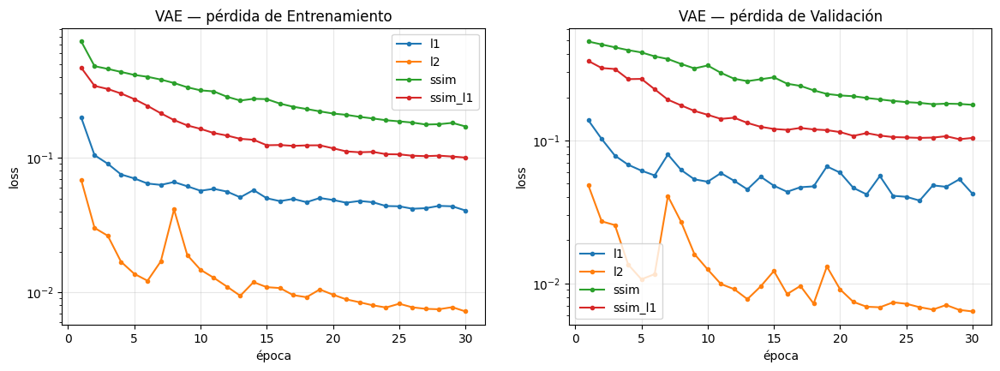

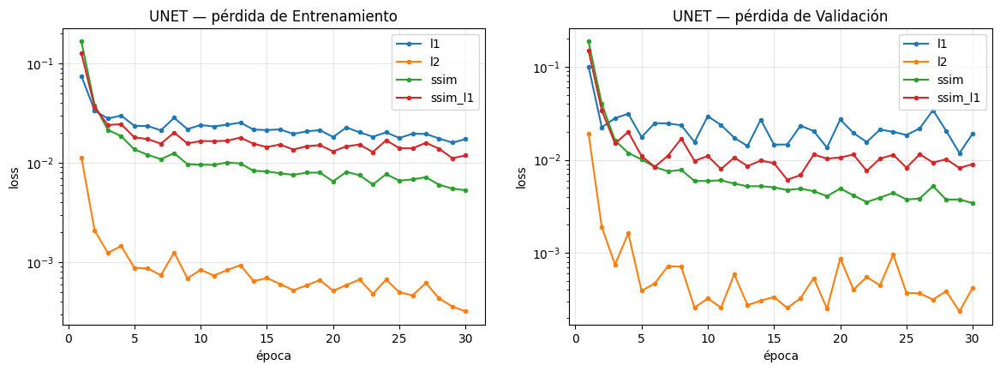

In [ ]:
def historia(run, clave):
    """Descarga de WandB la métrica `clave` por época."""
    try:
        h = run.history(keys=['epoch', clave], samples=5000, pandas=True)
    except Exception as e:
        print(f'  ({run.name}: no pude leer {clave}: {e})')
        return pd.Series(dtype=float)
    if h is None or len(h) == 0 or clave not in h:
        return pd.Series(dtype=float)
    h = h.dropna(subset=[clave])
    if 'epoch' in h:
        return h.groupby('epoch')[clave].last()
    return h[clave].reset_index(drop=True)

for m in fase1:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for l, r in fase1[m].items():
        if not r: continue
        for ax, clave in zip(axes, ['train/loss_epoch', 'val/loss']):
            h = historia(r, clave)
            if len(h):
                ax.plot(h.index + 1, h.values, marker='.', label=l)
    for ax, t in zip(axes, ['Entrenamiento', 'Validación']):
        ax.set_title(f'{m.upper()} — pérdida de {t}'); ax.set_xlabel('época'); ax.set_ylabel('loss')
        ax.set_yscale('log'); ax.grid(alpha=.3); ax.legend()
    plt.show()

Las curvas de train/loss y val/loss (descargadas de WandB, arriba) muestran la evolución por época de cada run. Dos cosas:

1. Forma vs. escala. L1, L2 y 1-SSIM tienen escalas distintas, así que no comparamos el valor absoluto, sino la forma: convergencia y estabilidad.
2. Brecha VAE vs. U-Net. La U-Net termina con pérdidas mucho más bajas que el VAE (su val/mse ~1e-4 frente a ~5e-3 en la tabla de 5.2), porque las skip connections le dejan reconstruir casi a la perfección.

Para saber cuál reconstruye y detecta mejor usamos las métricas comparables de 5.2.

### 5.2 Métricas comparables entre configuraciones
Estas métricas se calculan igual en todos los runs, sin importar con qué pérdida se entrenó:
- val/mse, val/l1: error de reconstrucción en validación (menor = mejor)
- val/ssim: similitud estructural en validación (mayor = mejor)
- AUROC: qué tan bien el error separa piezas buenas de defectuosas en prueba (1 = perfecto, 0.5 = azar)


In [ ]:
CATS = ['cable', 'capsule', 'screw', 'transistor']
def metricas(r):
    s = r.summary
    d = {'val/mse': s.get('val/mse'), 'val/l1': s.get('val/l1'), 'val/ssim': s.get('val/ssim'),
         'AUROC mse (prom.)': s.get('test/auroc_mse_mean'),
         'AUROC ssim (prom.)': s.get('test/auroc_ssim_err_mean')}
    for c in CATS:
        d[f'AUROC mse {c}'] = s.get(f'test/auroc_mse_{c}')
    return d

tabla = pd.DataFrame({r.name: metricas(r) for m in fase1 for r in fase1[m].values() if r}).T
tabla.style.format('{:.4f}').highlight_max(subset=['val/ssim', 'AUROC mse (prom.)', 'AUROC ssim (prom.)'], color='#c6efce') \
           .highlight_min(subset=['val/mse', 'val/l1'], color='#c6efce')

,val/mse,val/l1,val/ssim,AUROC mse (prom.),AUROC ssim (prom.),AUROC mse cable,AUROC mse capsule,AUROC mse screw,AUROC mse transistor
vae-l1,0.0037,0.0377,0.7980,0.5853,0.5561,0.7504,0.5756,0.2986,0.7167
vae-l2,0.0044,0.0415,0.7626,0.5330,0.6081,0.7344,0.5868,0.0969,0.7138
vae-ssim,0.0051,0.0535,0.8359,0.7661,0.6921,0.7335,0.6294,0.9926,0.7088
vae-ssim_l1,0.0033,0.0337,0.8434,0.6079,0.6623,0.7562,0.5529,0.3900,0.7325
unet-l1,0.0005,0.0192,0.9816,0.3545,0.3277,0.4472,0.5253,0.0174,0.4279
unet-l2,0.0004,0.0151,0.9848,0.5498,0.3115,0.6302,0.4041,1.0000,0.1650
unet-ssim,0.0001,0.0075,0.9966,0.5254,0.3342,0.4597,0.5114,0.6799,0.4508
unet-ssim_l1,0.0002,0.0103,0.9923,0.3736,0.2996,0.5135,0.5365,0.0027,0.4417


La tabla de 5.2 resume la calidad de cada configuración. Tres conclusiones:

1. Mejor reconstrucción: la U-Net domina claramente (val/ssim ≈ 0.98-0.997, val/mse ≈ 1e-4-5e-4). El VAE reconstruye peor (val/ssim ≈ 0.76-0.84), como se espera por el KL que regulariza.
2. Mejor detección: no coincide con la mejor reconstrucción. El mejor AUROC promedio lo logra vae-ssim (0.766), mientras la U-Net se queda en 0.35-0.55. Reconstruir mejor no implica detectar mejor: al reconstruir también los defectos, el error de la U-Net no resalta la anomalía.
3. Categoría más difícil: screw es la más inestable (AUROC de 0.097 en vae-l2 a 1.000 en unet-l2, pasando por 0.003 en unet-ssim_l1). Sus defectos son chicos (rayones en cabeza o cuello, rosca), así que el error promedio por imagen casi no cambia.

### 5.3 Reconstrucciones del set de validación (16 imágenes, última época)
Pares original | reconstrucción.


**vae-l1** — `val/reconstrucciones`

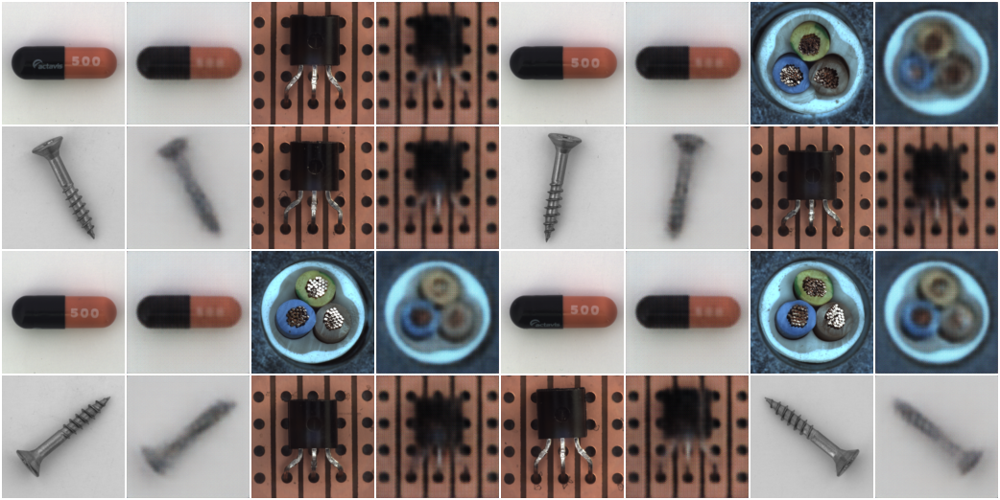

**vae-l2** — `val/reconstrucciones`

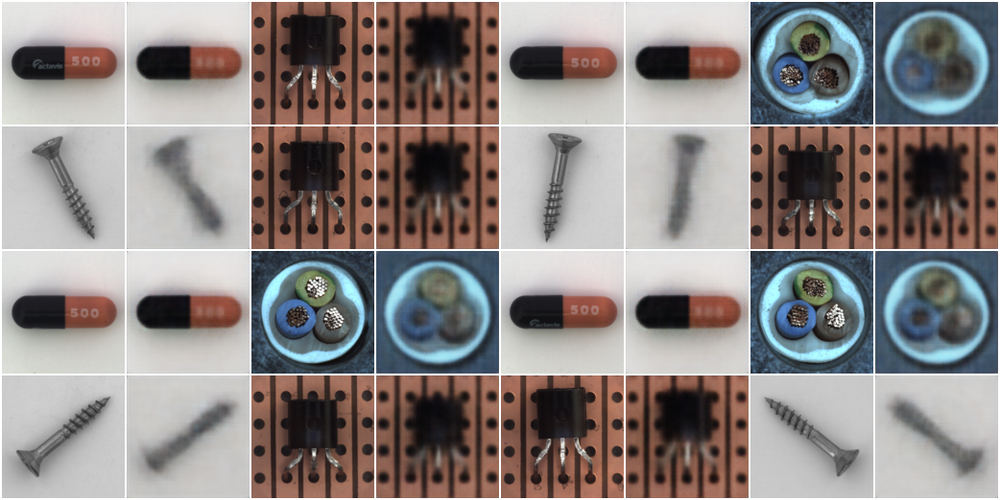

**vae-ssim** — `val/reconstrucciones`

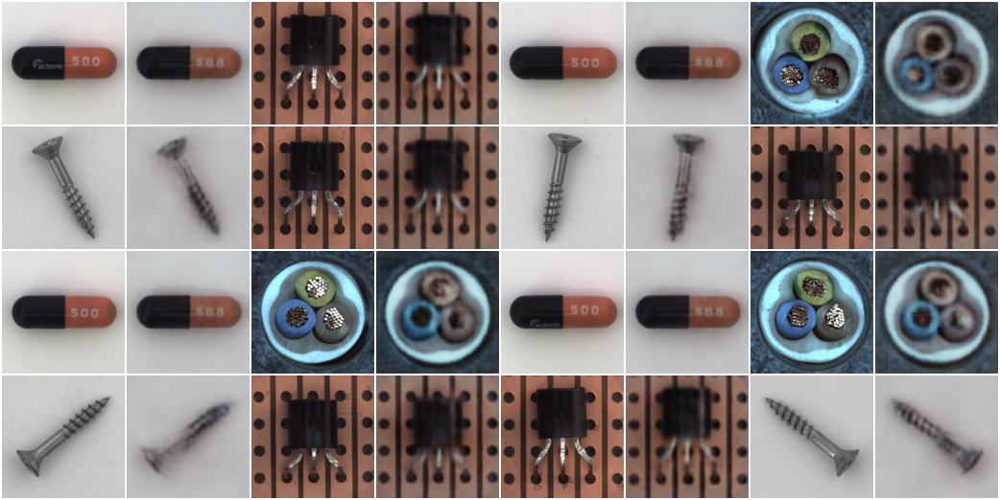

**vae-ssim_l1** — `val/reconstrucciones`

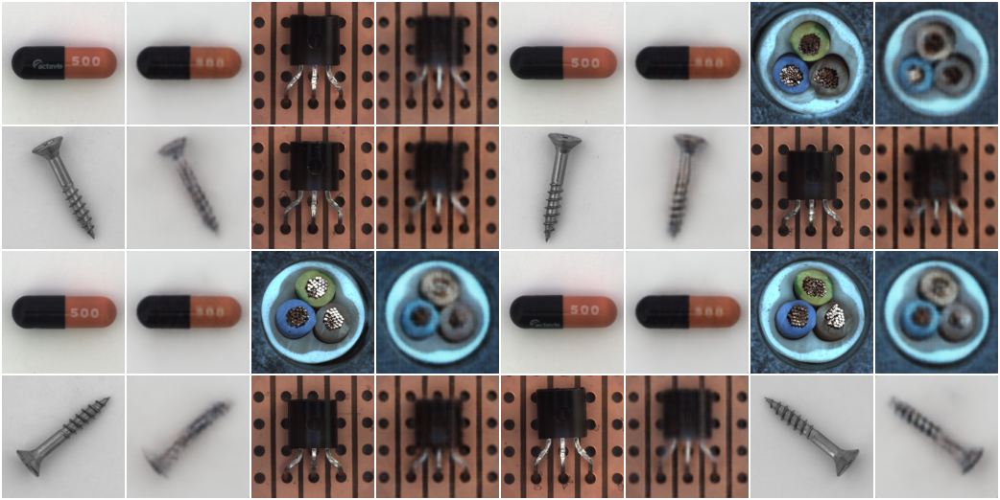

**unet-l1** — `val/reconstrucciones`

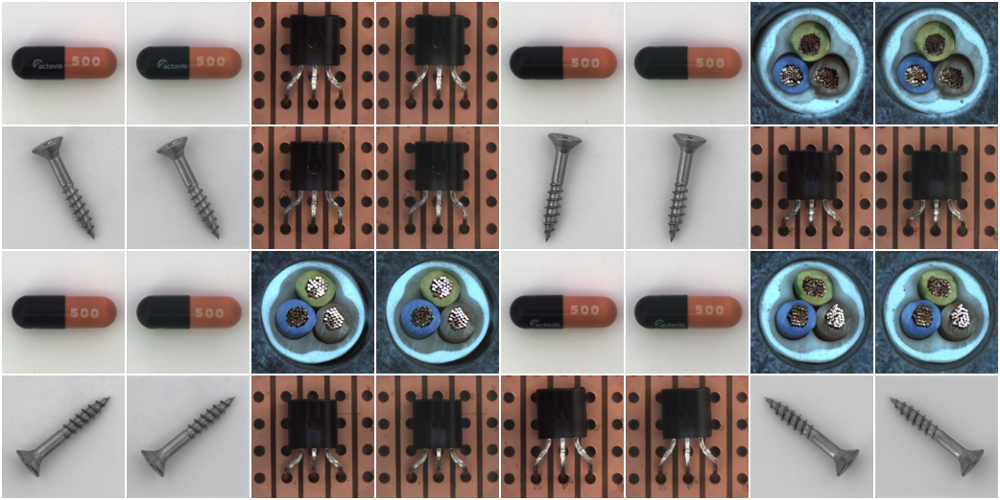

**unet-l2** — `val/reconstrucciones`

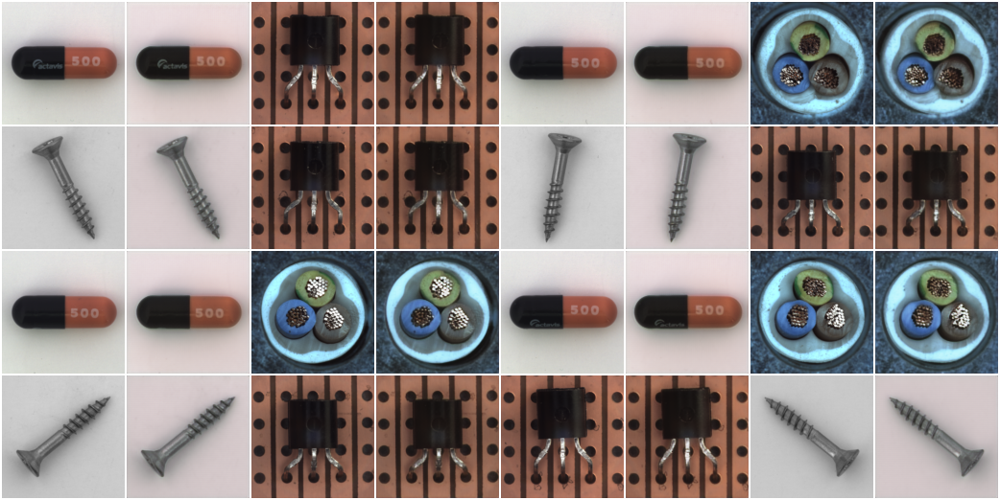

**unet-ssim** — `val/reconstrucciones`

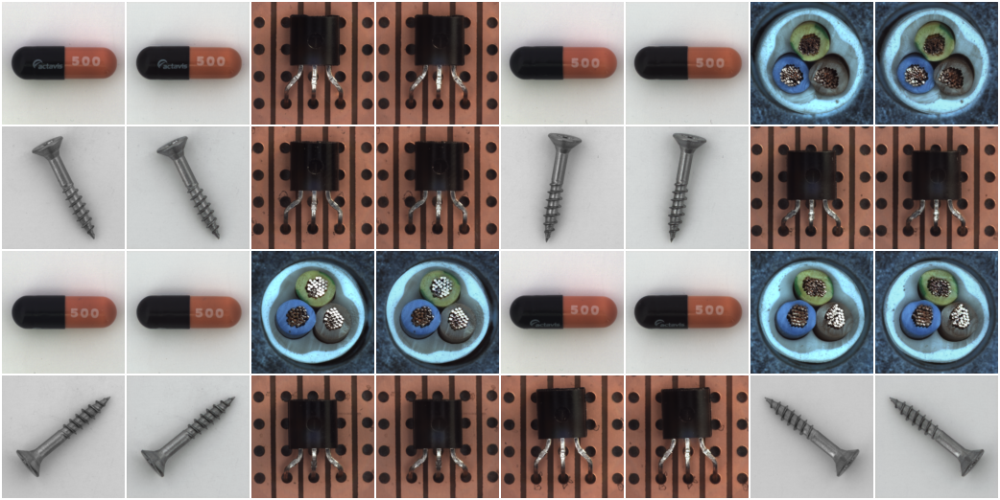

**unet-ssim_l1** — `val/reconstrucciones`

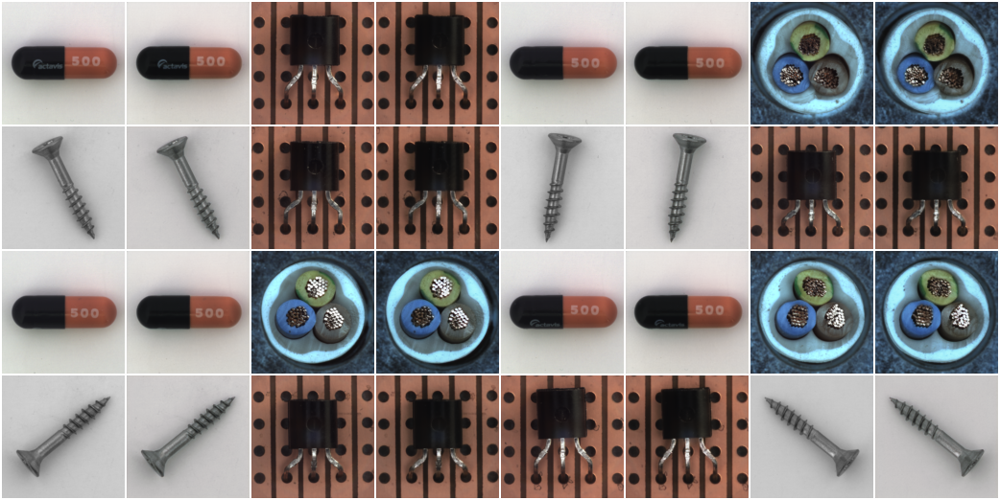

In [ ]:
for m in fase1:
    for l, r in fase1[m].items():
        if r: mostrar(r, 'val/reconstrucciones', ancho=800)

En las reconstrucciones de validación (pares original | reconstrucción) se ve la diferencia de nitidez entre arquitecturas y pérdidas:

- VAE: reconstrucciones más borrosas, sobre todo con L2 (suaviza); SSIM y SSIM+L1 conservan mejor los bordes.
- U-Net: reconstrucciones casi idénticas al original, gracias a las skip connections.
- Efecto de la pérdida: las pérdidas basadas en SSIM tienden a dar mayor val/ssim que L1 o L2, en línea con la tabla de 5.2.

### 5.4 Espacio latente con t-SNE a lo largo de las épocas
Izquierda: validación coloreada por categoría. Derecha: prueba, buenas (verde) vs defectuosas (rojo).


**vae-ssim** — tsne_80_89bc9d299c026181d95a.png

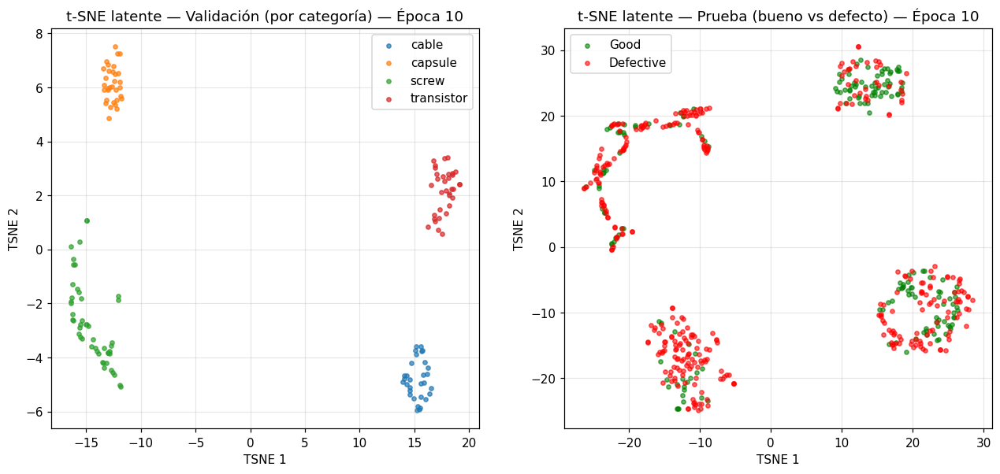

**vae-ssim** — tsne_163_eba5921f3d5d5c1fe49a.png

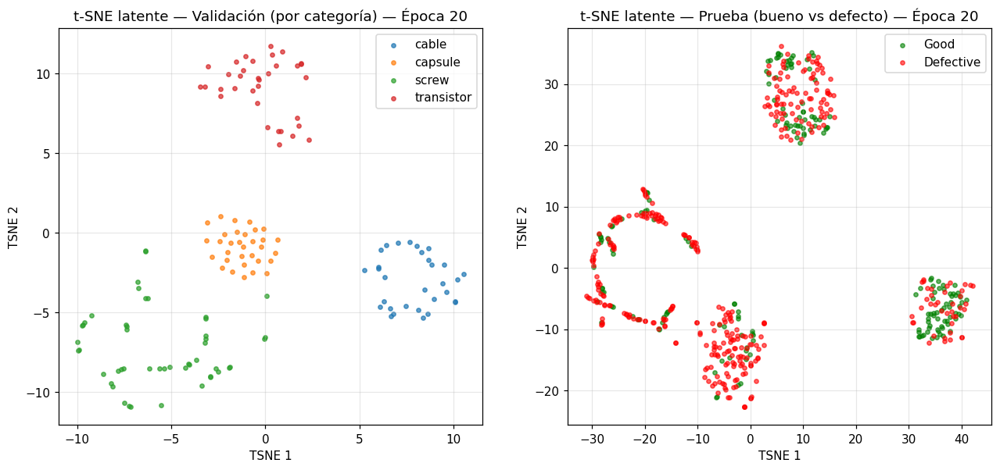

**vae-ssim** — tsne_246_514ddccffcfdca7a34d8.png

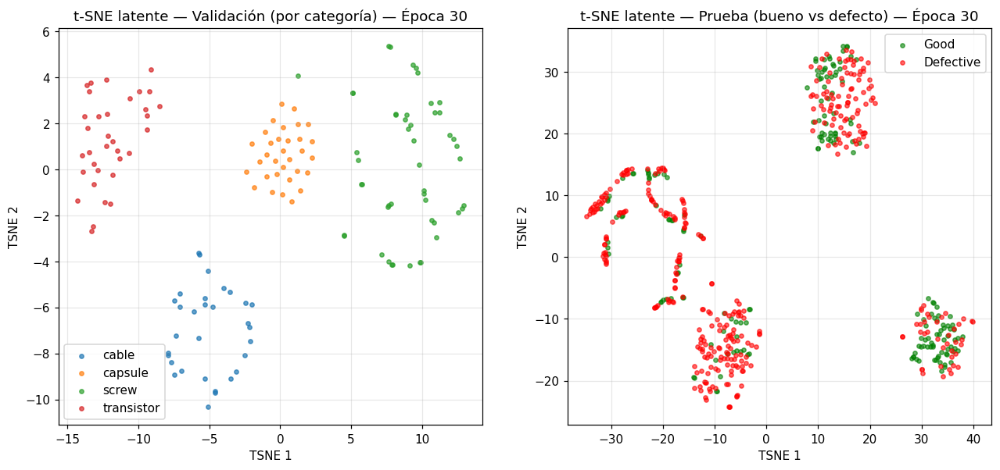

**unet-l2** — tsne_80_57326af12b1909a25085.png

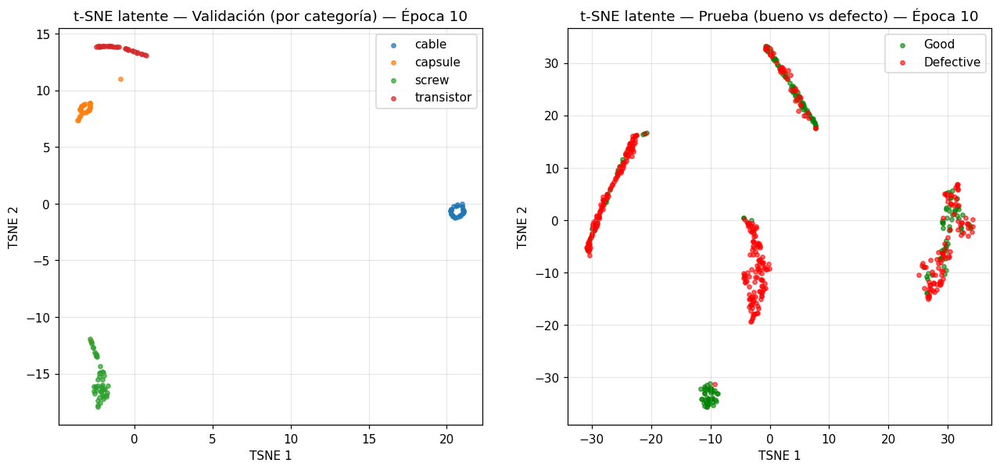

**unet-l2** — tsne_163_fb362ccfb2cb7f477901.png

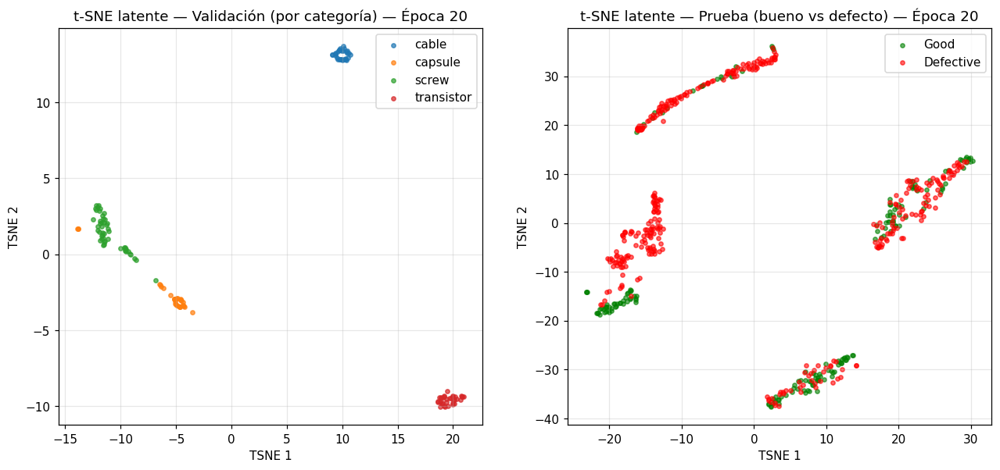

**unet-l2** — tsne_246_c257a4c6c3af3c27a471.png

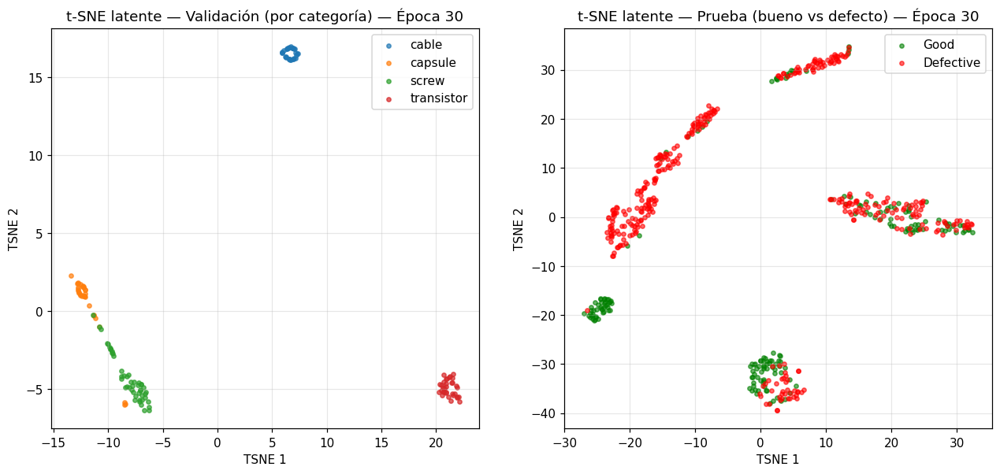

In [ ]:
# Evolución por épocas para el mejor run de cada modelo (según AUROC)
def mejor(m):
    rs = [r for r in fase1[m].values() if r]
    return max(rs, key=lambda r: r.summary.get('test/auroc_mse_mean') or 0)

for m in fase1:
    r = mejor(m)
    for ruta in imagenes(r, 'latente/tsne'):
        display(Markdown(f'**{r.name}** — {os.path.basename(ruta)}'))
        display(Image(ruta, width=900))

**vae-l1** — `latente/tsne`

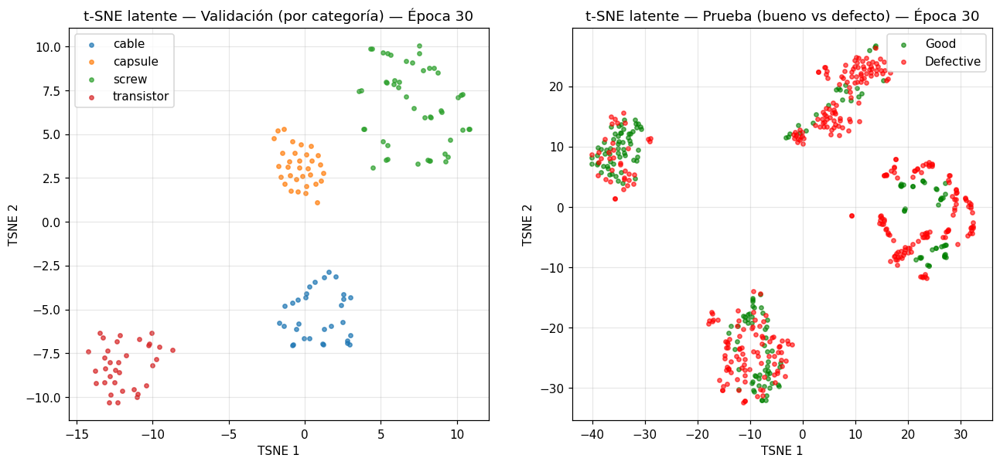

**vae-l2** — `latente/tsne`

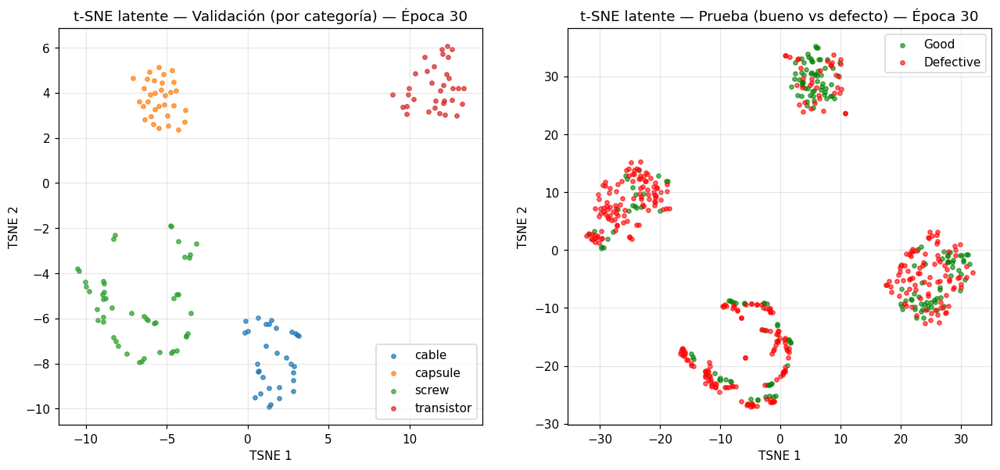

**vae-ssim** — `latente/tsne`

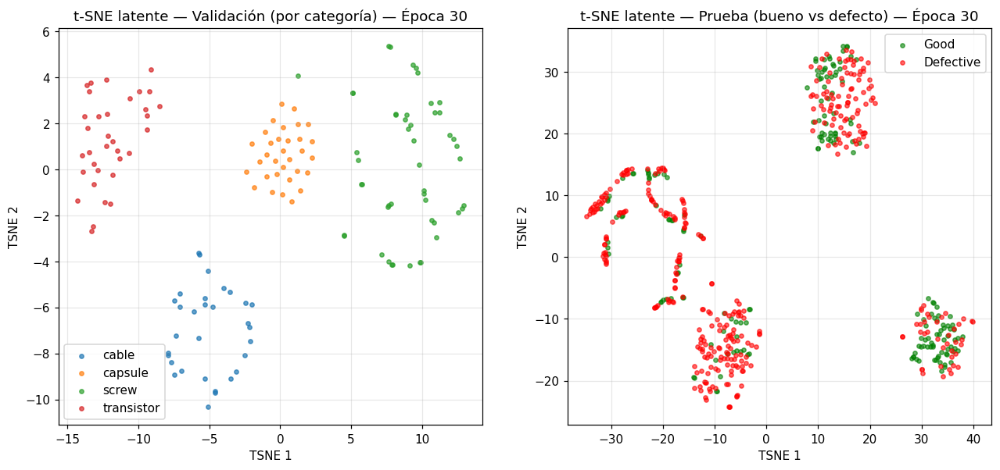

**vae-ssim_l1** — `latente/tsne`

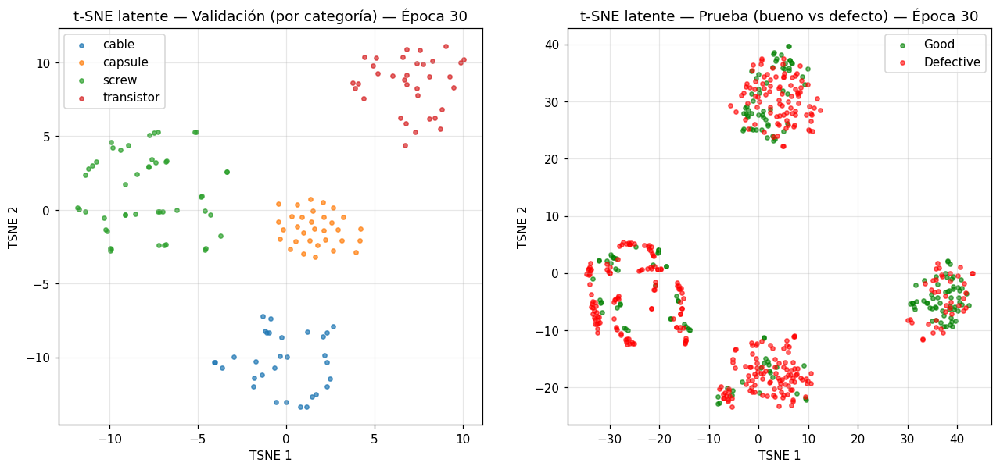

**unet-l1** — `latente/tsne`

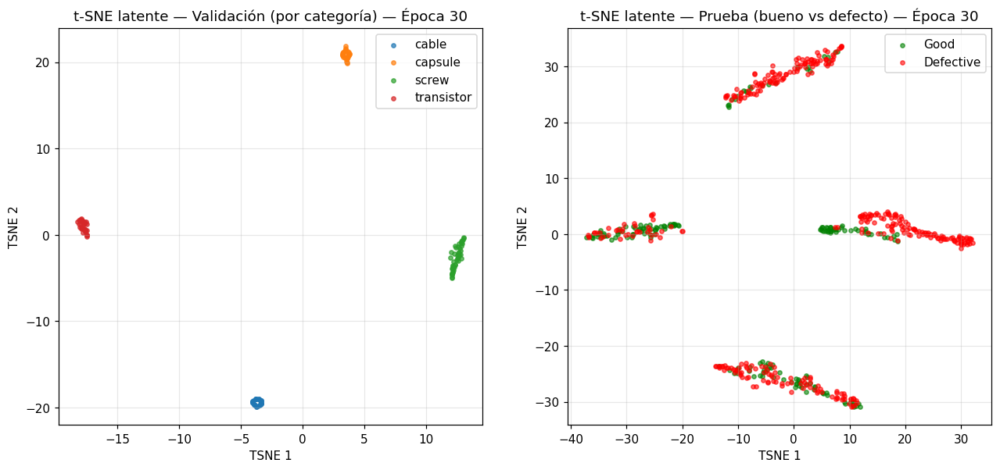

**unet-l2** — `latente/tsne`

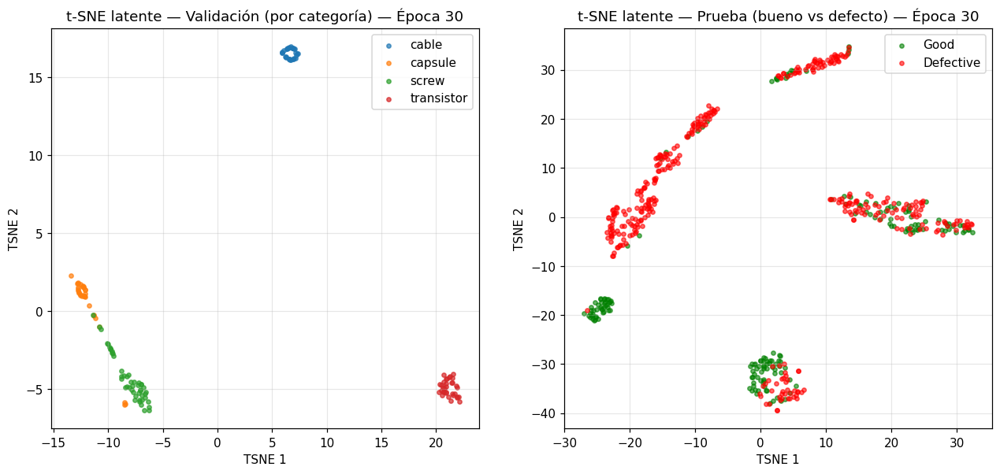

**unet-ssim** — `latente/tsne`

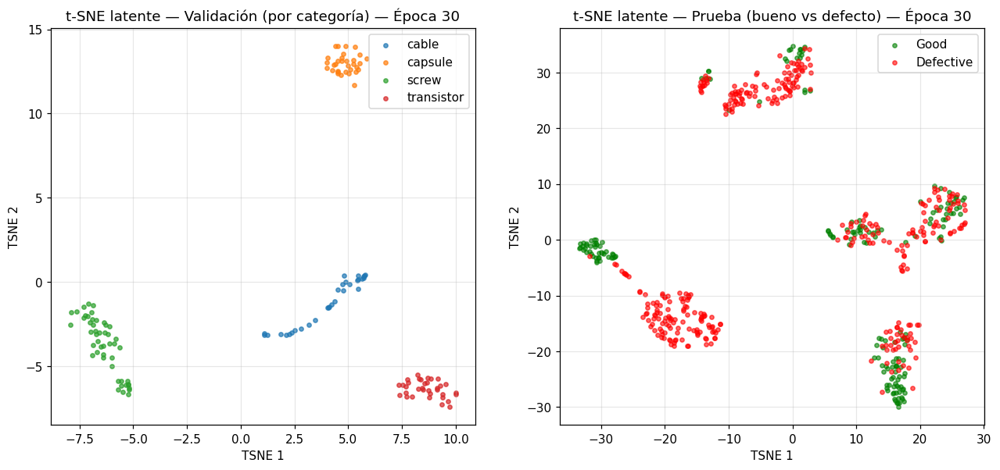

**unet-ssim_l1** — `latente/tsne`

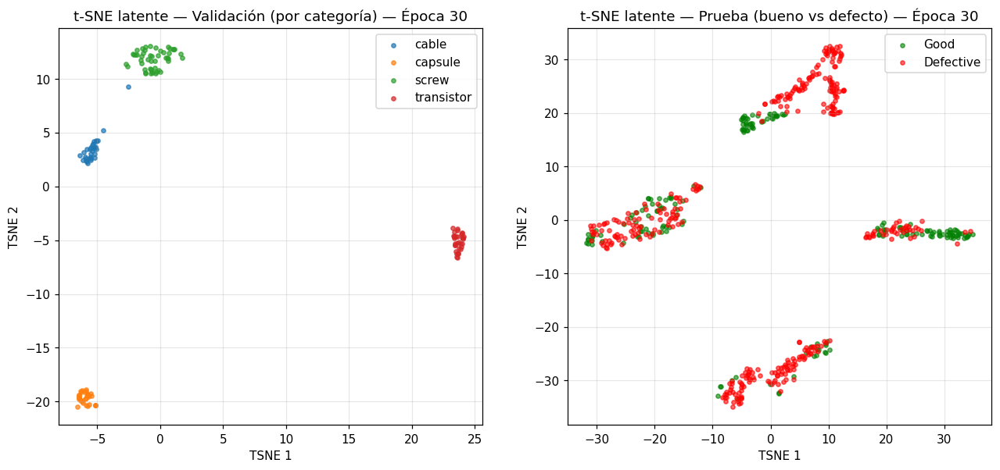

In [ ]:
# t-SNE final de todos los runs, para comparar entre pérdidas
for m in fase1:
    for l, r in fase1[m].items():
        if r: mostrar(r, 'latente/tsne', ancho=700)

El t-SNE del vector latente permite ver dos cosas:

- Separación por categoría (validación, izquierda): las 4 clases forman clusters distinguibles en ambos modelos. El VAE tiende a clusters redondeados; la U-Net, a filamentos alargados y más apretados.
- Buenas vs. defectuosas (prueba, derecha): en el VAE los verdes y rojos están muy entremezclados, casi sin frontera. En la U-Net aparecen zonas casi puras de un solo color, así que separa algo mejor lo bueno de lo defectuoso en el latente.

Esa separación, con todo, no se traduce en mejor detección: la U-Net separa más en el latente pero tiene AUROC más bajos (0.35-0.55) que el VAE (hasta 0.77). Lo que usamos para detectar es el error de reconstrucción en píxeles, no la geometría del latente, y ahí el VAE sale ganando. En este caso el t-SNE y el AUROC no van de la mano. Dos precauciones: el t-SNE es cualitativo (sus distancias no son interpretables) y en prueba hay muchas más defectuosas que buenas, así que las zonas casi rojas en parte reflejan ese desbalance.

### 5.5 Reconstrucción de imágenes buenas y con anomalías (set de prueba, 16 imágenes)
Fila 1: original, fila 2: reconstrucción, fila 3: mapa de error. Títulos en verde = buena, rojo = defecto.


**vae-l1** — `test/reconstrucciones`

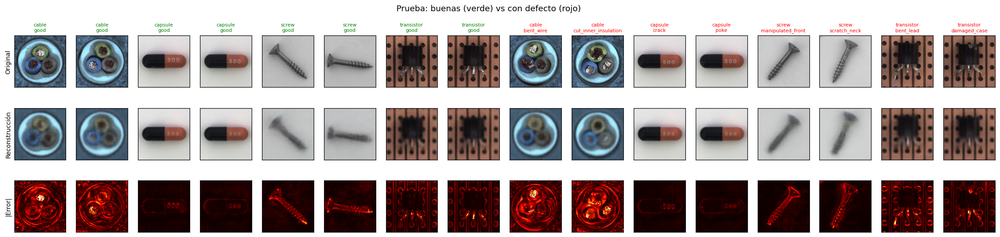

**vae-l2** — `test/reconstrucciones`

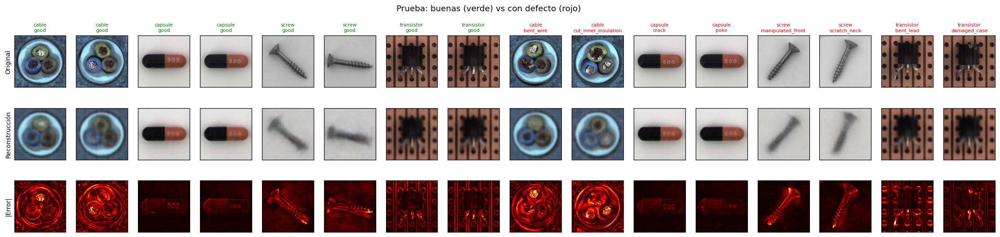

**vae-ssim** — `test/reconstrucciones`

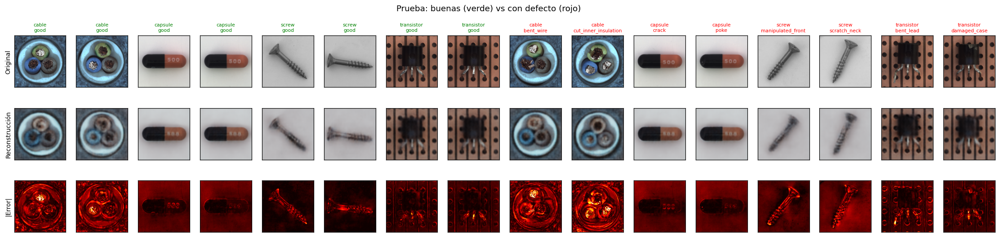

**vae-ssim_l1** — `test/reconstrucciones`

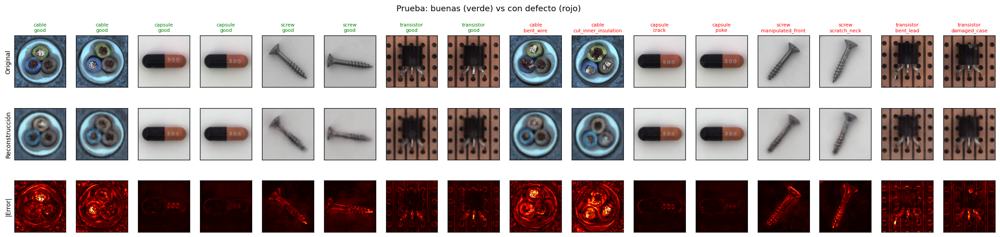

**unet-l1** — `test/reconstrucciones`

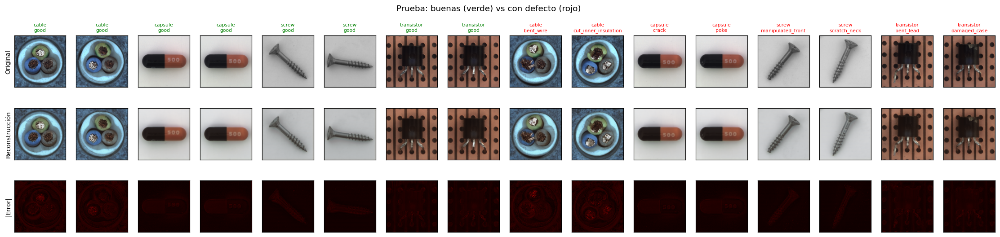

**unet-l2** — `test/reconstrucciones`

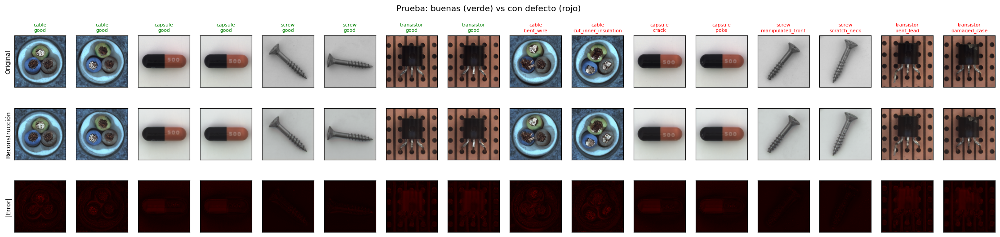

**unet-ssim** — `test/reconstrucciones`

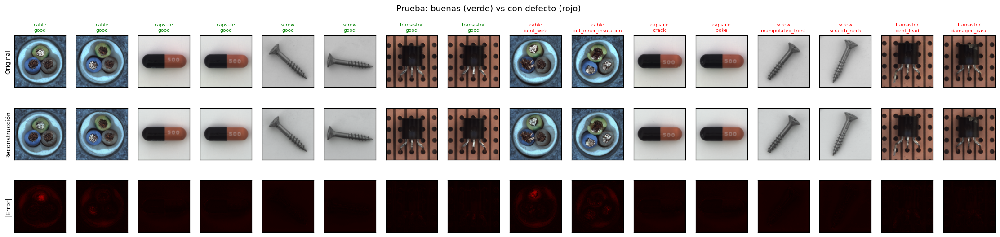

**unet-ssim_l1** — `test/reconstrucciones`

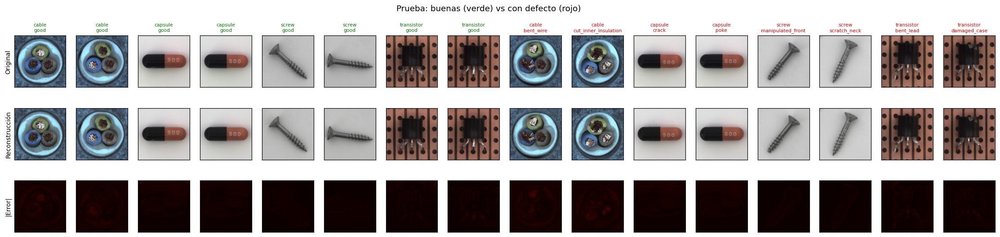

In [ ]:
for m in fase1:
    for l, r in fase1[m].items():
        if r: mostrar(r, 'test/reconstrucciones', ancho=1100)

En las reconstrucciones de prueba (fila 1 original, fila 2 reconstrucción, fila 3 mapa de error) se busca si el mapa de error resalta el defecto:

- VAE: como reconstruye borroso, las piezas buenas dejan un error residual bajo y uniforme, y las defectuosas suelen mostrar un pico localizado en la zona del defecto. Esa es la señal que usamos para detectar.
- U-Net: reconstruye también el defecto (las skip connections lo copian), así que el mapa de error queda casi plano incluso donde debería ser alto. Eso explica sus AUROC bajos pese al excelente val/ssim.

### 5.6 Histogramas del error de reconstrucción: normales vs cada subclase de defecto


**vae-l1** — `test/histogramas_mse`

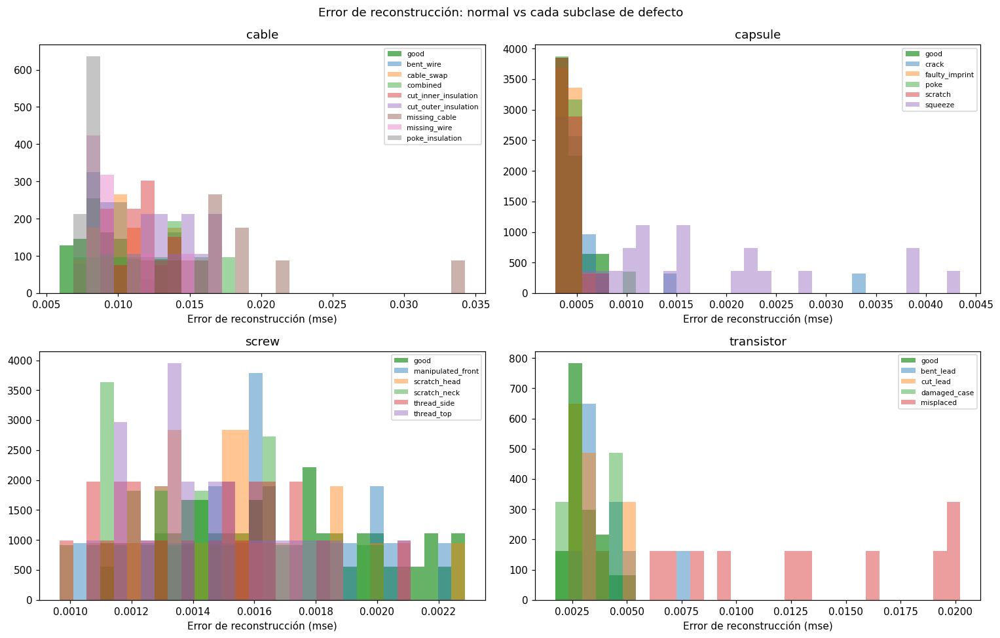

**vae-l2** — `test/histogramas_mse`

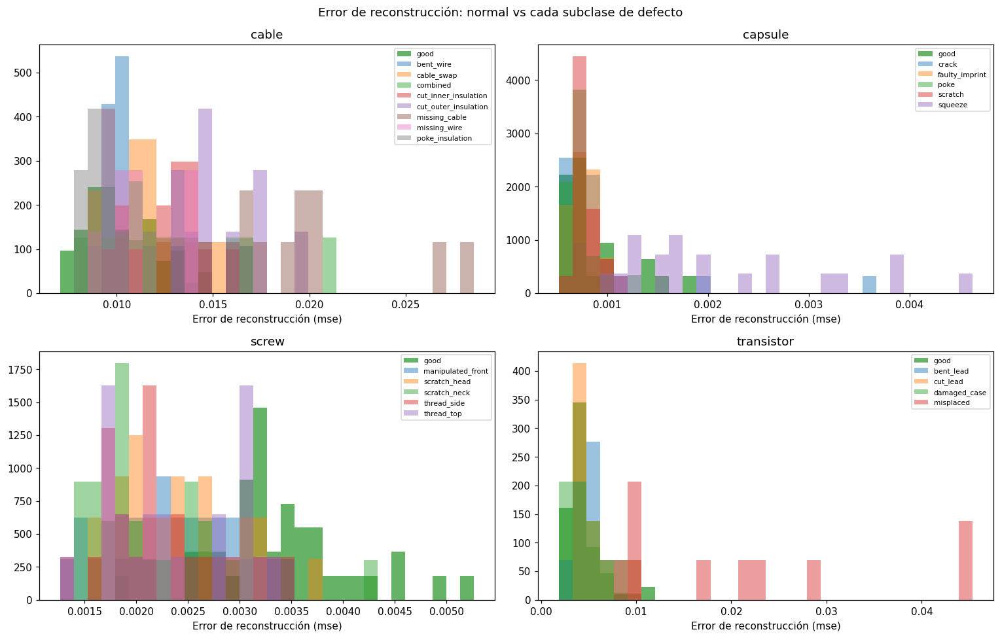

**vae-ssim** — `test/histogramas_mse`

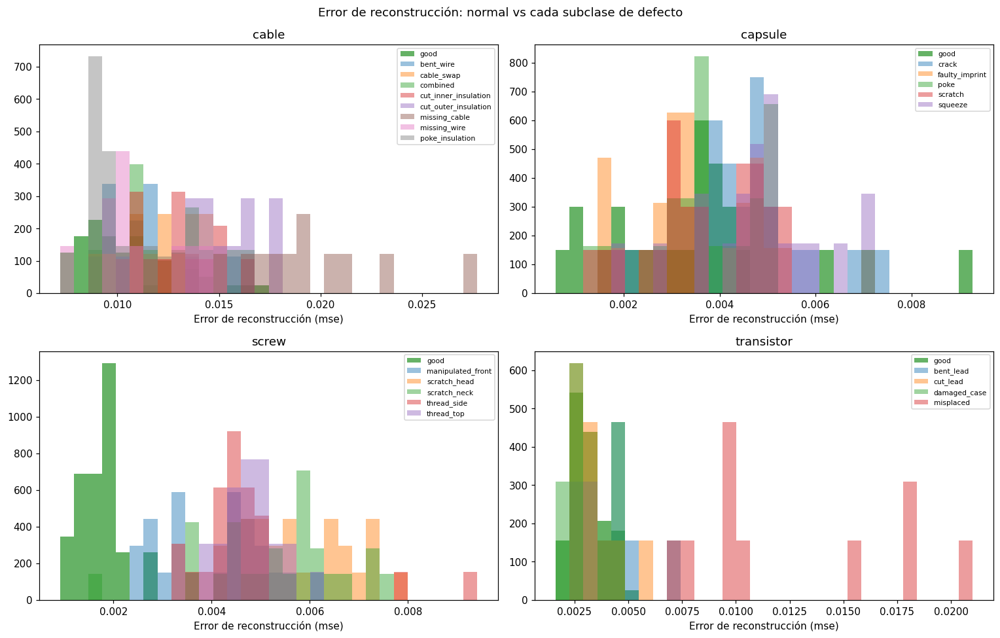

**vae-ssim_l1** — `test/histogramas_mse`

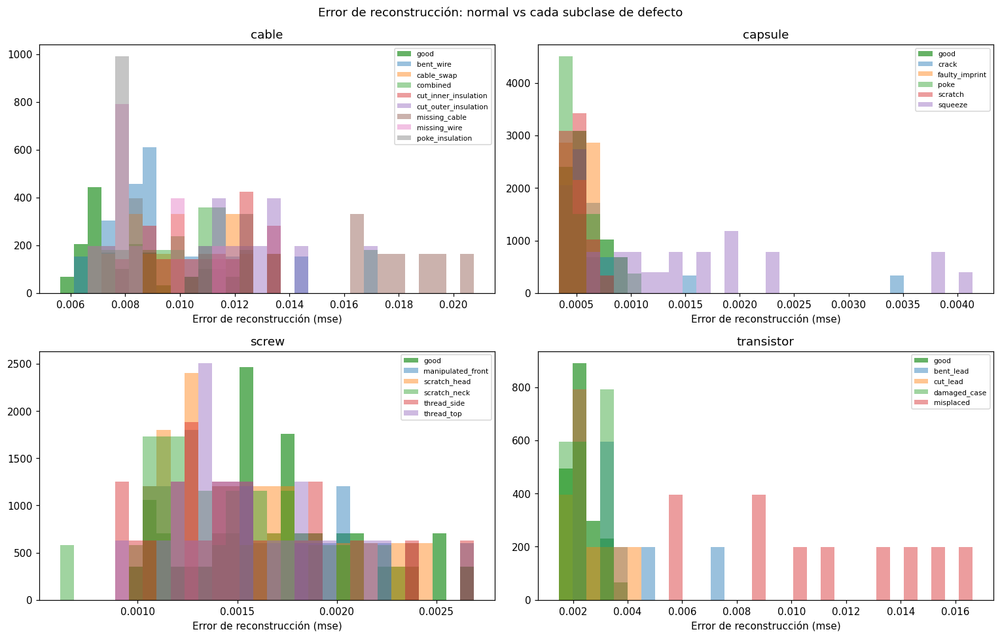

**unet-l1** — `test/histogramas_mse`

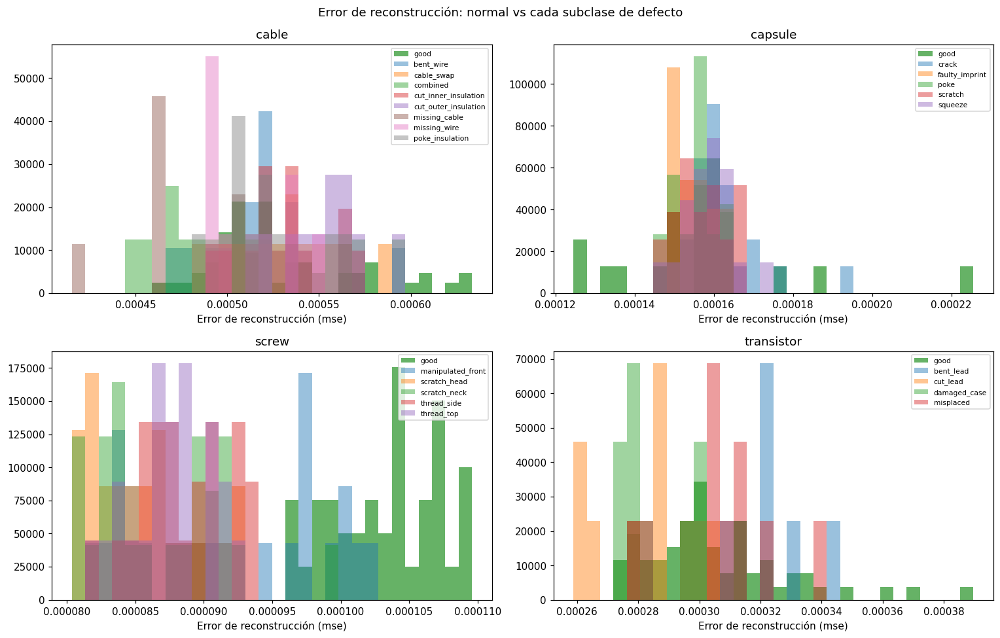

**unet-l2** — `test/histogramas_mse`

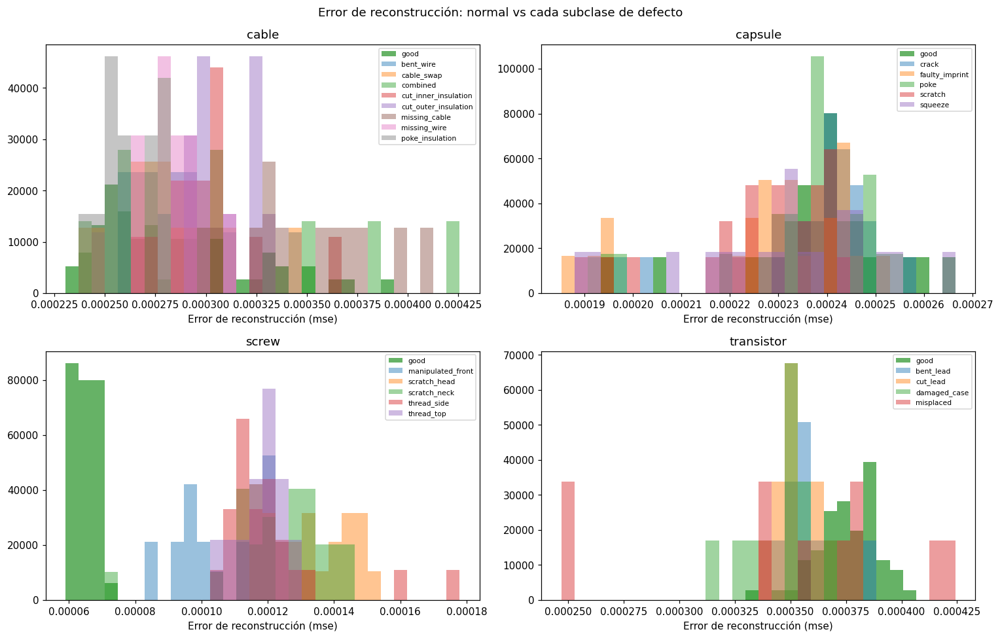

**unet-ssim** — `test/histogramas_mse`

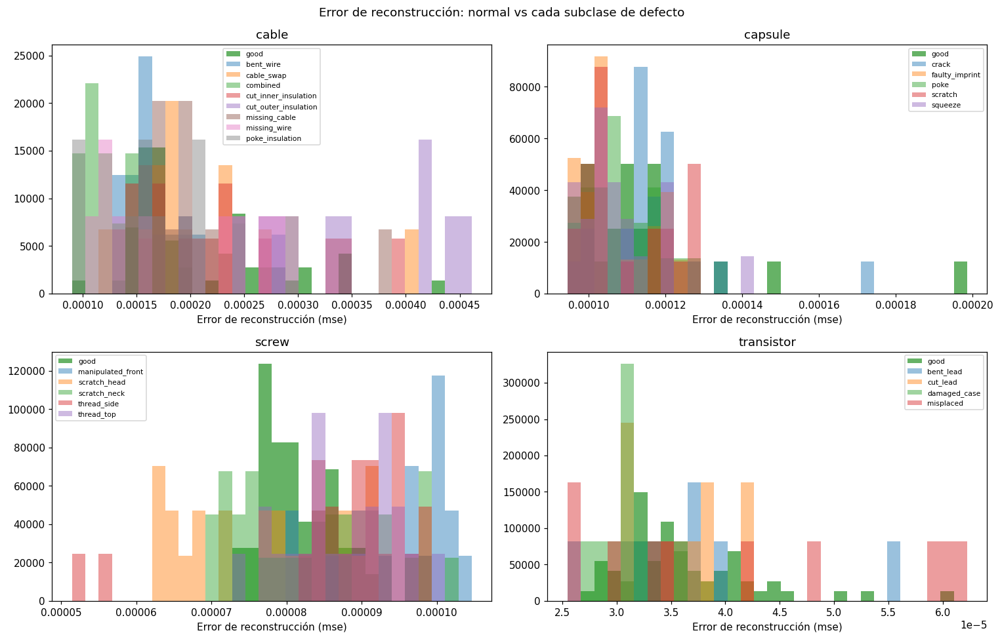

**unet-ssim_l1** — `test/histogramas_mse`

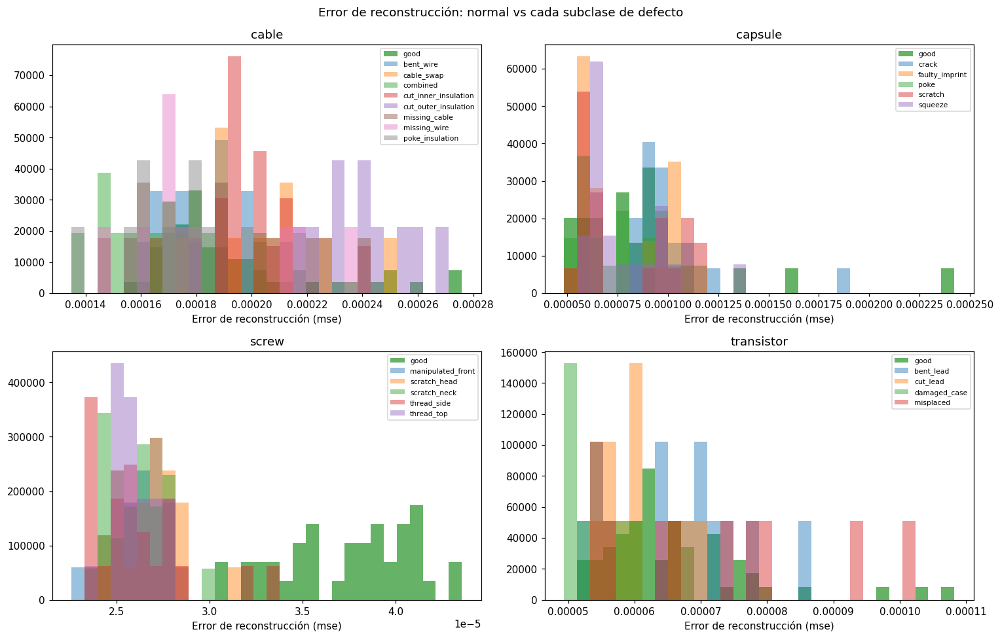

In [ ]:
for m in fase1:
    for l, r in fase1[m].items():
        if r: mostrar(r, 'test/histogramas_mse', ancho=900)

**vae-ssim** — `test/histogramas_ssim_err`

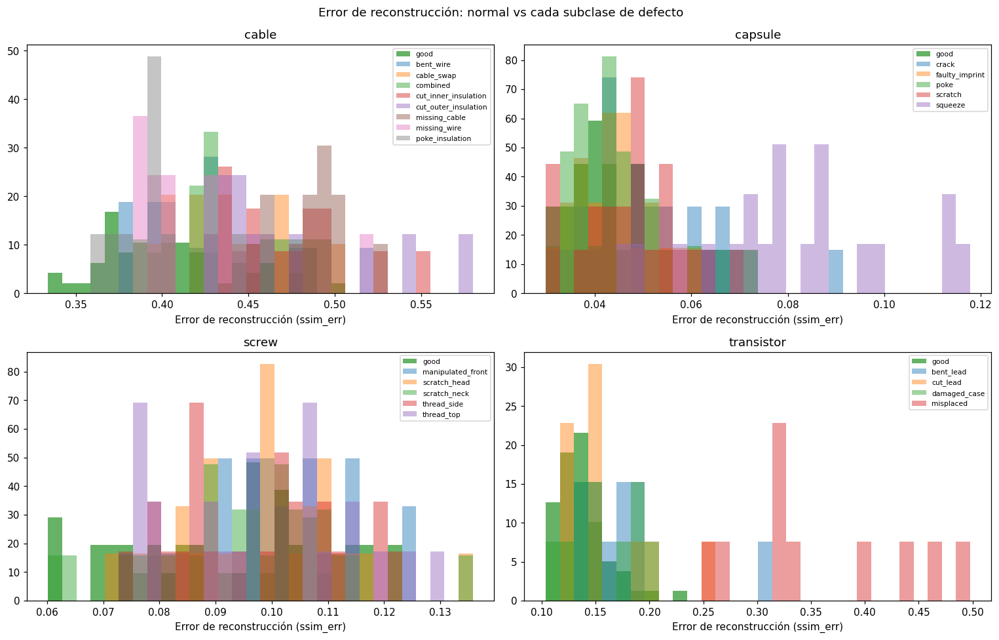

**unet-l2** — `test/histogramas_ssim_err`

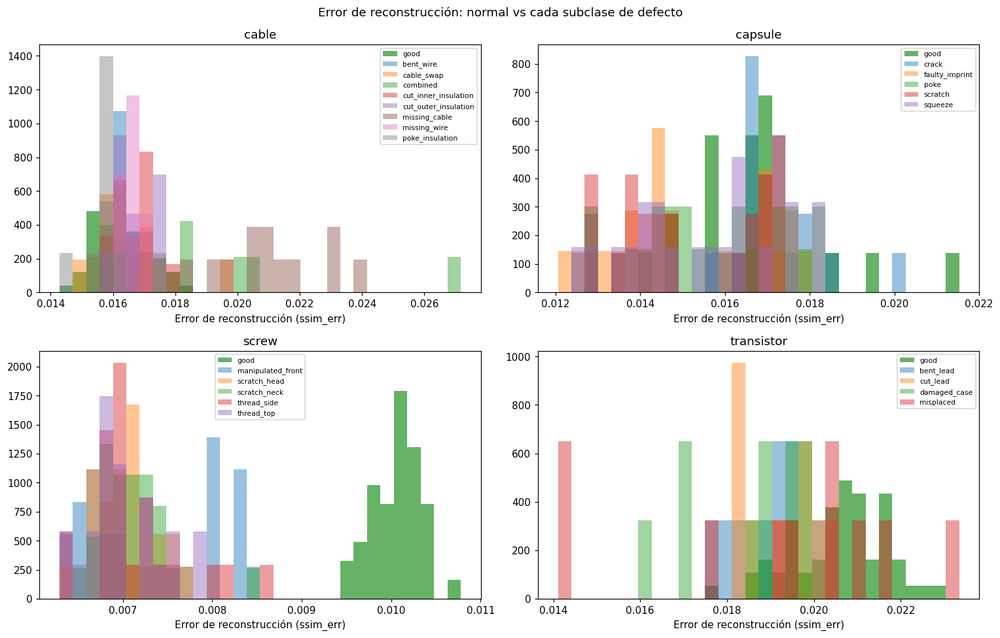

In [ ]:
# (Opcional) mismos histogramas con el error 1-SSIM para el mejor run de cada modelo
for m in fase1:
    mostrar(mejor(m), 'test/histogramas_ssim_err', ancho=900)

Los histogramas comparan la distribución del error de reconstrucción de las piezas buenas (verde) contra cada subclase de defecto:

- Subclases bien separadas: cuando el histograma del defecto queda corrido a la derecha (mayor error) respecto al de good, el error sirve para detectarlo. Pasa con defectos grandes o muy visibles (missing_cable, misplaced en transistor).
- Subclases que se solapan: los defectos chicos o de textura fina (scratch_neck en screw, rayones en capsule) producen un error parecido al de las buenas, y sus histogramas se superponen. Por eso screw tiene AUROC tan inestables en 5.2.
- Dos métricas: los histogramas usan mse (y 1-SSIM para los mejores runs), que capturan cosas distintas del error.


## 6. Experimentos adicionales (fase 2)
Con la mejor pérdida de la fase 1 se probó:
- VAE con `latent_dim` = 32 y 128 (base: 64)
- VAE con `kl_weight` = 0.001 y 0.01 (base: 0.005)
- U-Net sin las 2 skip connections de mayor resolución

,val/mse,val/ssim,AUROC mse (prom.),AUROC ssim (prom.)
(base) vae-ssim_l1,0.0033,0.8434,0.6079,0.6623
(base) unet-ssim,0.0001,0.9966,0.5254,0.3342
unet-ssim_l1-sin-skips-altas,0.0012,0.9660,0.5475,0.4633
vae-ssim_l1-kl0.001,0.0036,0.8287,0.6878,0.6253
vae-ssim_l1-kl0.01,0.0034,0.8363,0.5811,0.6634
vae-ssim_l1-z128,0.0046,0.7975,0.6064,0.6048
vae-ssim_l1-z32,0.0037,0.8298,0.5230,0.6363


**unet-ssim_l1-sin-skips-altas** — `test/reconstrucciones`

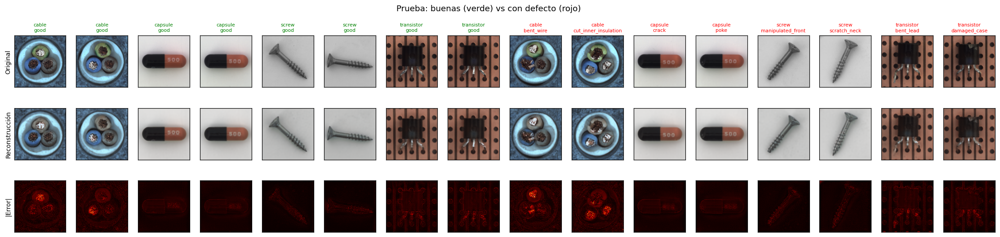

**unet-ssim_l1-sin-skips-altas** — `latente/tsne`

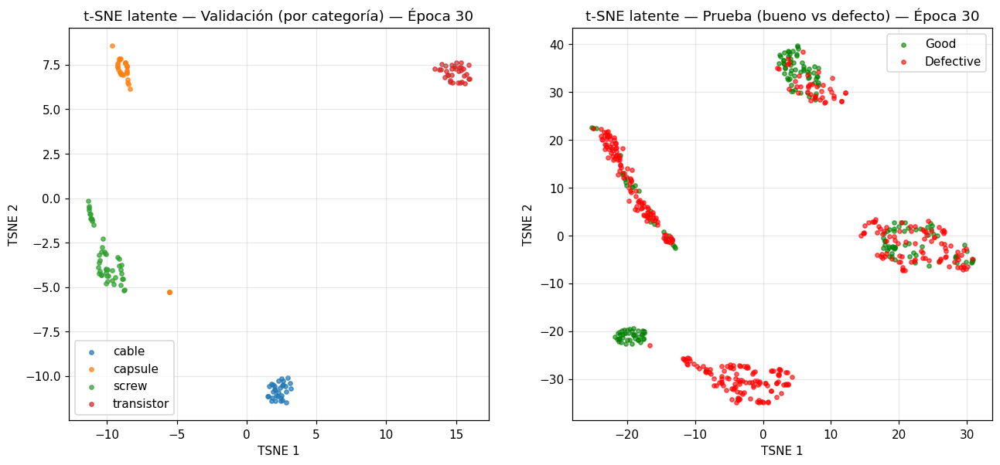

**vae-ssim_l1-kl0.001** — `test/reconstrucciones`

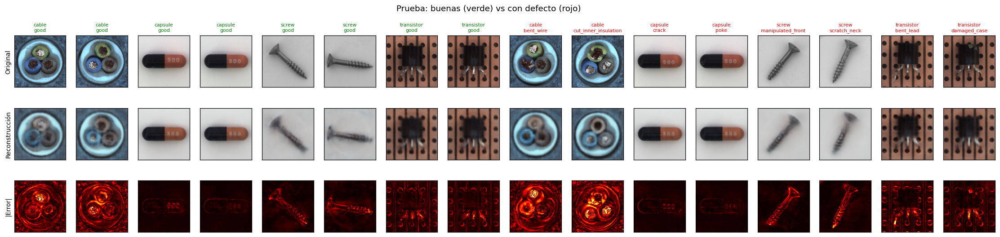

**vae-ssim_l1-kl0.001** — `latente/tsne`

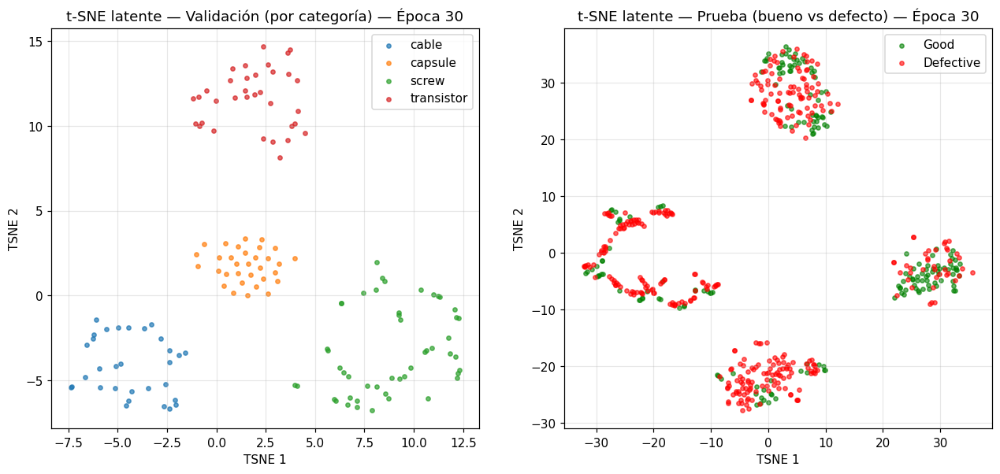

**vae-ssim_l1-kl0.01** — `test/reconstrucciones`

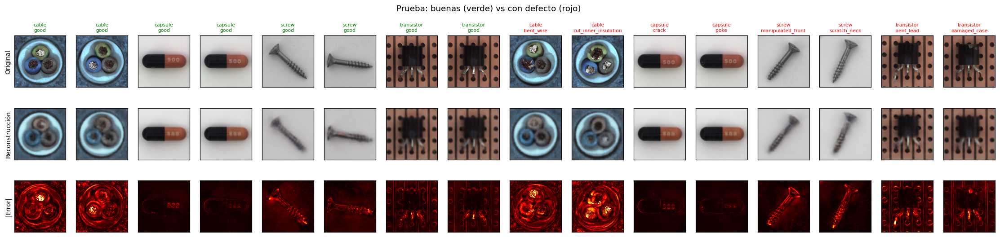

**vae-ssim_l1-kl0.01** — `latente/tsne`

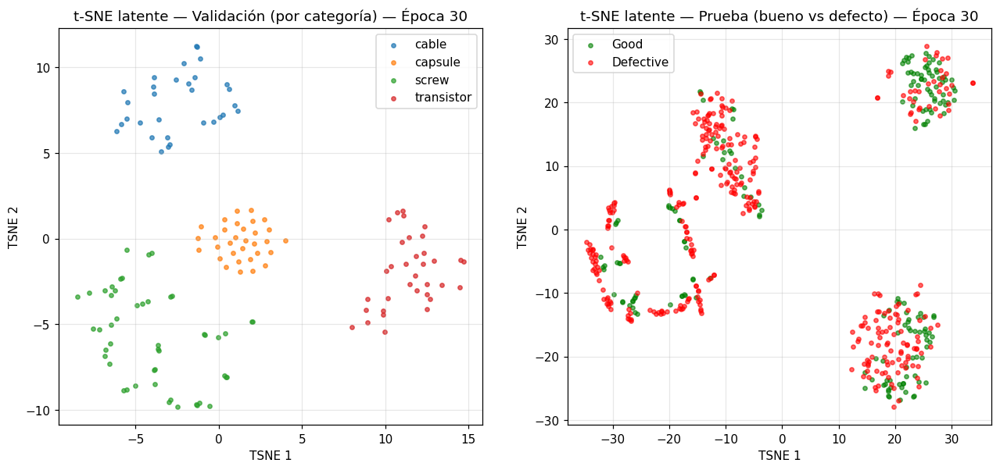

**vae-ssim_l1-z128** — `test/reconstrucciones`

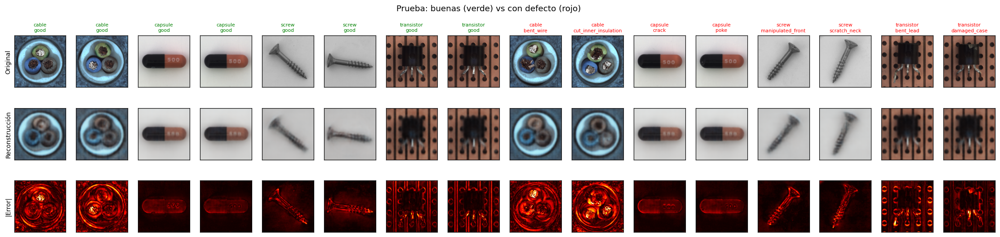

**vae-ssim_l1-z128** — `latente/tsne`

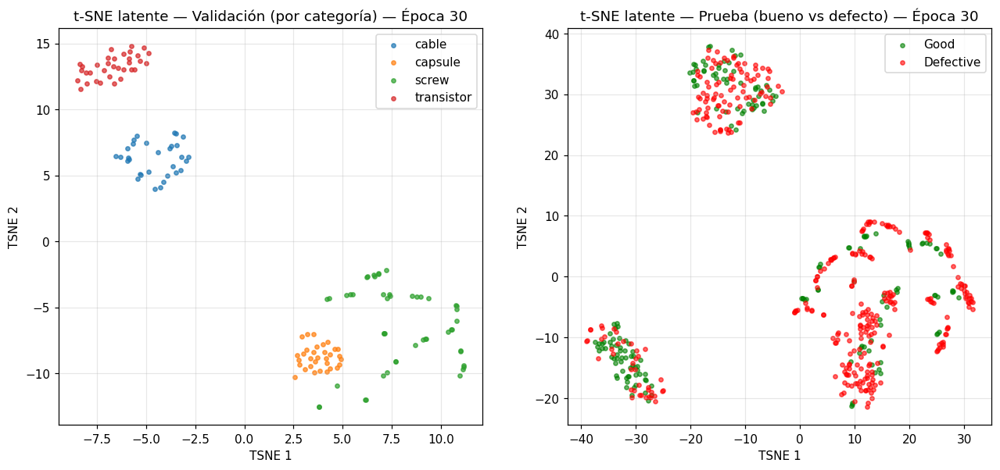

**vae-ssim_l1-z32** — `test/reconstrucciones`

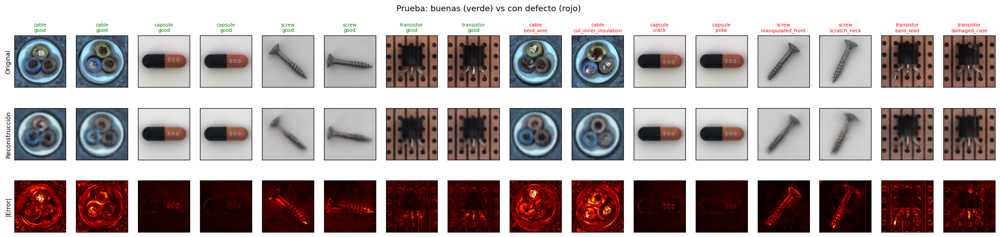

**vae-ssim_l1-z32** — `latente/tsne`

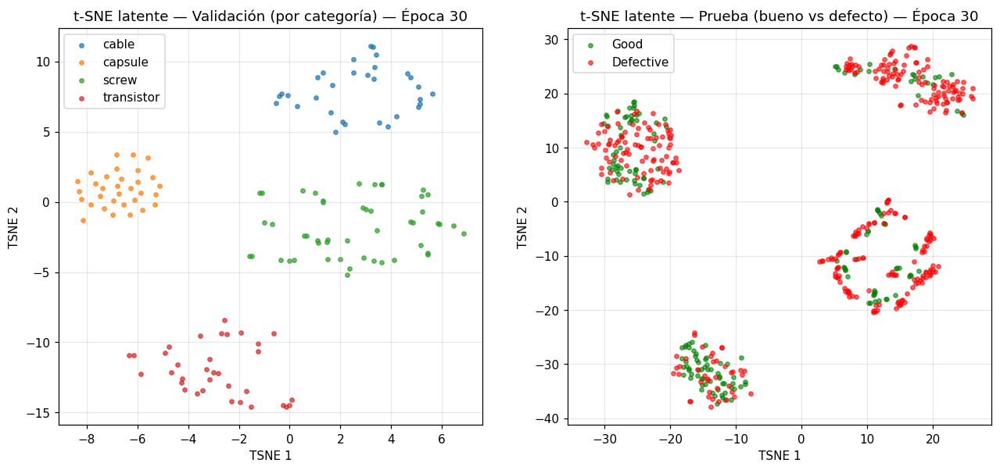

In [ ]:
if extras:
    base = {m: max([r for r in fase1[m].values() if r],
                   key=lambda r: r.summary.get('val/ssim') or 0) for m in fase1}
    comp = {f'(base) {base[m].name}': metricas(base[m]) for m in base}
    comp.update({n: metricas(r) for n, r in sorted(extras.items())})
    display(pd.DataFrame(comp).T[['val/mse', 'val/ssim', 'AUROC mse (prom.)', 'AUROC ssim (prom.)']].style.format('{:.4f}'))
    for n, r in sorted(extras.items()):
        mostrar(r, 'test/reconstrucciones', ancho=1100)
        mostrar(r, 'latente/tsne', ancho=700)
else:
    print('No hay runs de la fase 2')

Los experimentos de la fase 2 (tabla de arriba) exploran qué pasa al variar el cuello del VAE y las skips de la U-Net:

- Latente más chico (z=32): el AUROC baja (0.523 frente a 0.608 de la base z=64). Un cuello muy estrecho pierde información útil.
- Latente más grande (z=128): empeora val/ssim (0.797) y no mejora la detección (0.606). Más capacidad no ayuda.
- β menor (kl=0.001): sube la detección a 0.688, la mejor de la fase 2. Un KL más débil deja al VAE reconstruir mejor lo normal y diferenciarse de lo anómalo.
- Quitar las 2 skips de mayor resolución en la U-Net: el AUROC sube de 0.525 a 0.548 y val/ssim baja de 0.997 a 0.966. Sin esas skips el modelo no copia tan fácil los defectos y el error vuelve a ser informativo.


## 7. Análisis crítico

1. ¿Qué pérdida reconstruye mejor y cuál detecta mejor? ¿Coinciden?
No coinciden. Para reconstruir, las pérdidas basadas en SSIM dominan: vae-ssim_l1 (val/ssim 0.843) y unet-ssim (0.997) son las mejores de cada modelo. Para detectar anomalías, el mejor es vae-ssim (AUROC mse 0.766), y dentro del VAE ssim_l1 baja a 0.608. Una reconstrucción más fiel no se traduce en mejor separación.

2. VAE vs. U-Net: ¿quién reconstruye y quién detecta mejor?
La U-Net reconstruye mucho mejor (val/ssim ~0.98-0.997 frente a ~0.76-0.84) pero detecta peor (AUROC 0.35-0.55 frente a hasta 0.77 del VAE). La causa son las skip connections: reinyectan las activaciones del encoder en el decoder y dejan pasar información que rodea al cuello de botella, así que el modelo puede copiar el defecto en vez de borrarlo. El error deja de ser informativo. El VAE, con su cuello estricto y el KL, reconstruye borroso pero falla más cuando ve algo anómalo, que es justo lo que necesitamos.

3. ¿Qué categorías y subclases fueron más fáciles o difíciles?
cable y transistor son las más estables (AUROC mse ~0.71-0.76 en el VAE): sus defectos (cables faltantes o intercambiados, patas dobladas o cortadas) son grandes y visibles. screw es la más difícil e inestable (AUROC 0.097-1.000 según la configuración): sus defectos (rayones en cabeza o cuello, rosca) son chicos y cambian poco el error promedio. El error promediado en toda la imagen es una señal débil para defectos de tamaño reducido.

4. ¿Qué muestra el t-SNE?
Muestra cómo codifica el modelo lo normal y lo anómalo en el latente. A la derecha (buenas verde vs defectuosas rojo), la U-Net separa algo más que el VAE, con zonas casi puras de un solo color; el VAE queda más entremezclado. Pero eso no mejora su detección: la U-Net separa más en el latente y aun así tiene AUROC más bajos. La razón es que detectamos con el error de reconstrucción en píxeles, no con la distancia en el latente. Y el t-SNE es cualitativo, con muchas más defectuosas que buenas en prueba, así que no hay que leerlo como una métrica dura.

5. Limitaciones.
Resolución fija de 128×128 (pierde detalle fino), solo 30 épocas, pocas imágenes de entrenamiento por categoría (~200-320) y un error promediado sobre toda la imagen que diluye defectos chicos. Además el split de validación es aleatorio sobre el conjunto bueno, no estratificado por categoría.

6. ¿Qué haríamos distinto?
- Usar un mapa de error localizado (parche por parche) en vez de un solo escalar por imagen, para captar defectos chicos.
- Stratificar el split de validación por categoría.
- Probar pérdidas perceptuales (VGG) o adversariales para mejorar nitidez sin perder detección.
- Ajustar β y la arquitectura por separado por categoría, porque screw se comporta muy distinto.

## 8. Conclusiones

1. Reconstruir bien no es lo mismo que detectar bien. La U-Net logra las mejores reconstrucciones (val/ssim ≈ 0.997) pero los AUROC más bajos; el VAE, más borroso, detecta mejor (AUROC hasta 0.77).
2. Las skip connections son un arma de doble filo: dan nitidez pero dejan copiar el defecto, y eso degrada la detección. Quitarlas (fase 2) sube el AUROC de la U-Net.
3. La mejor configuración de detección fue vae-ssim (AUROC mse 0.766), no la que mejor reconstruye.
4. El error de reconstrucción global es débil para defectos chicos (como en screw), así que conviene pasar a métricas localizadas por parche.
5. El KL y el tamaño del latente importan: un KL menor (0.001) y un latente de 64 dimensiones dieron el mejor equilibrio en la fase 2.
